# NIVELL 1

## Preparació general del notebook

### Llibreries i configuració global dels gràfics

Totes les llibreries es carreguen una sola vegada, a l'inici del notebook. `%matplotlib inline` mostra els gràfics dins del notebook i `rcParams` defineix una mida i un format generals per evitar repetir `figsize` o els paràmetres tipogràfics a cada visualització. L'amplada visual efectiva també depèn de l'entorn (Colab / VS Code).

In [2]:
# IMPORTS GENERALS: totes les llibreries en un únic lloc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from IPython.display import display
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Mostrar els gràfics dins del notebook
%matplotlib inline

# Configuració per defecte, compartida per tots els gràfics
plt.rcParams.update({
    "figure.figsize": (15, 6),
    "figure.dpi": 100,
    "figure.autolayout": True,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.grid": False,
})

## Exercici 1: Preguntes analítiques directes (sense integracions complexes)

Es treballa amb la taula `transactions` com a DataFrame independent. Cada pregunta segueix la mateixa estructura:

1. Preparació de dades i elecció del gràfic inicial.
2. **Gràfic inicial** i interpretació.
3. **Resposta original de Copilot** i **gràfic alternatiu proposat per la IA**.
4. Comparació crítica entre les dues visualitzacions i decisió justificada.

Així, en cada apartat es veuen **els dos gràfics que s'han de comparar**, sense repetir-los en altres seccions.

### Connexió i càrrega de les dades

Es realitza la connexió amb la base de dades MySQL `nova_bd_transactions`, allotjada en local. Un cop establerta la connexió, es comproven les taules i es carrega `transactions` a `df_transactions`. La contrasenya es demana durant l'execució i no es guarda al notebook.

In [3]:
# DEMANAR CONTRASENYA
password = getpass("Introdueix la contrasenya de MySQL: ")

# CONFIGURAR CONNEXIÓ
url = URL.create(
    drivername="mysql+pymysql",     # Controlador MySQL
    username="root",                # Usuari
    password=password,              # Contrasenya oculta
    host="localhost",               # Servidor
    port=3306,                      # Port
    database="nova_bd_transactions" # Nom de la teva base de dades
)

# CREAR MOTOR DE CONNEXIÓ
engine = create_engine(url)

# COMPROVAR CONNEXIÓ
with engine.connect() as conexion:
    resultat = conexion.execute(text("SELECT DATABASE();"))
    base_dades = resultat.scalar()

print(f"Connectada a la base de dades: {base_dades}")

Connectada a la base de dades: nova_bd_transactions


In [4]:
taules = pd.read_sql("SHOW TABLES;", engine)

display(taules)

,Tables_in_nova_bd_transactions
0,companies
1,credit_cards
2,products
3,transaction_products
4,transactions
5,users
6,vistamarketing


In [5]:
df_transactions = pd.read_sql(
    "SELECT * FROM transactions",
    engine
)

display(df_transactions.head())

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.19992926158272,1.4355402821327607,34.17,72.25,0.00,online,SUMMER_TRAVEL,mobile,0,,59.95
1,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,CcS-5019,b-2370,2016-12-21 20:07:18,172.56,0,"66, 69, 87",438,41.59720554463741,12.22175994259365,19.92,29.86,6.99,online,CHRISTMAS_PEAK,tablet,0,,494.51
2,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757295899964348,-95.37963676492454,16.10,22.47,0.00,store,SUMMER_TRAVEL,pos,1,,1157.10
3,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.54888376797025,-113.50305274646564,1.05,14.45,0.00,store,NO_CAMPAIGN,pos,0,,540.32
4,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.20836951654172,5.690806474241335,25.31,25.96,8.99,marketplace,WINTER_SALE,desktop,0,,28.52


### 1. Com evoluciona el nombre de transaccions al llarg del temps?

**Preparació de dades.** Selecciono `timestamp` i el converteixo a `datetime`. Escullo l'escala **anual** per veure la tendència global sense saturar l'eix temporal. Compto les transaccions per any amb `value_counts()` i ordeno cronològicament amb `sort_index()`. En aquest recompte incloc tant les transaccions acceptades com les rebutjades, perquè la pregunta demana el **nombre de transaccions**, no només les vendes acceptades.

In [6]:
display(df_transactions.dtypes)
df_transactions["timestamp"] = pd.to_datetime(df_transactions["timestamp"])

df_transactions["any"] = df_transactions["timestamp"].dt.year
display(df_transactions["timestamp"].dtype)

total_transactions_anuals = df_transactions["any"].value_counts().sort_index()
display(total_transactions_anuals)

id                  str
card_id             str
business_id         str
timestamp           str
amount              str
declined            str
product_ids         str
user_id             str
lat                 str
longitude           str
discount_amount     str
tax_amount          str
shipping_amount     str
channel             str
campaign_id         str
device_type         str
is_international    str
decline_reason      str
distance_km         str
dtype: object

dtype('<M8[us]')

any
2015     9870
2016     9855
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
Name: count, dtype: int64

**Selecció del gràfic inicial.** Les variables són `any` (temporal, eix X) i nombre de transaccions (quantitativa, eix Y). Utilitzo un **gràfic de línies amb Pandas** per mostrar l'evolució temporal. **Mantinc l'eix Y sense començar a zero**, tal com a la primera versió: això permet veure canvis petits però també en pot exagerar visualment la magnitud. Ho tindré en compte en comparar-lo amb la proposta de la IA.

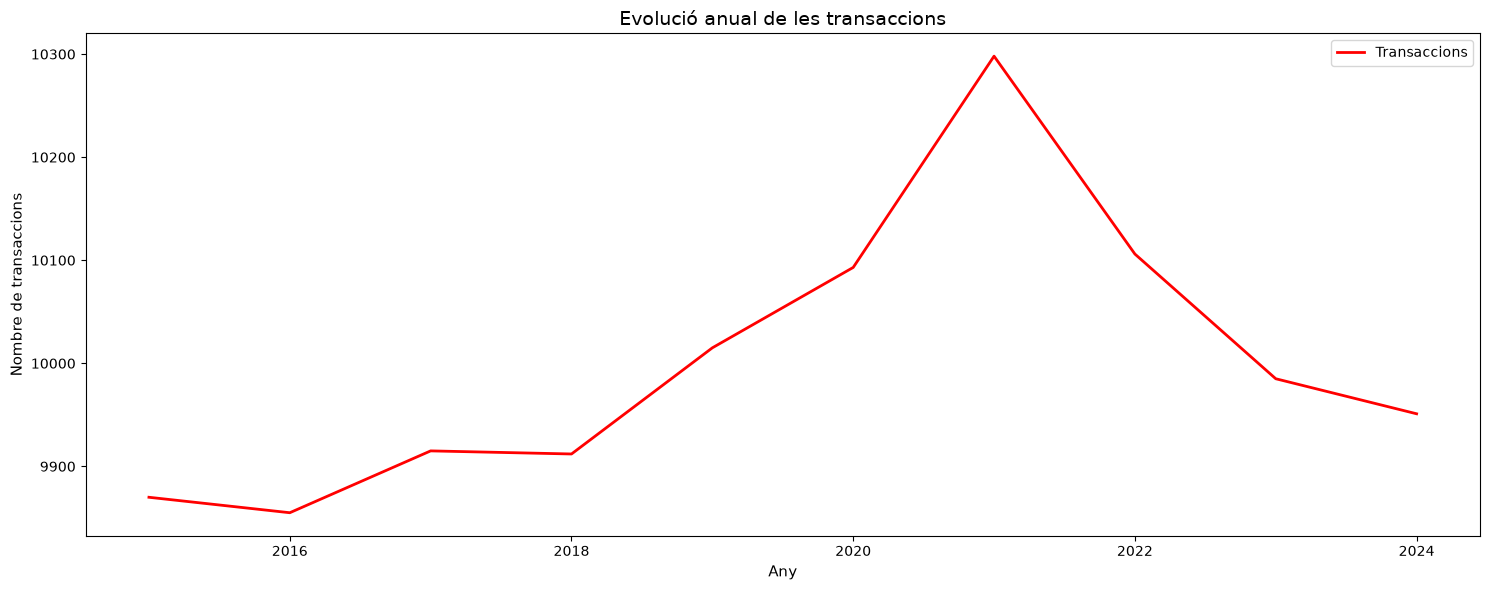

In [7]:
ax = total_transactions_anuals.plot(
    kind="line",
    color="red",
    label="Transaccions",
    linewidth=2
)
ax.set_title("Evolució anual de les transaccions")
ax.set_xlabel("Any")
ax.set_ylabel("Nombre de transaccions")
ax.legend()

plt.show()

**Interpretació.** S'observa una tendència de creixement general entre 2015 i 2021, quan s'assoleix el màxim de **10.298 transaccions**. A partir de 2021 es registra una baixada: **10.106 (2022)**, **9.985 (2023)** i **9.951 (2024)**. El gràfic de línies permet apreciar la tendència, però l'eix Y, que comença prop de 9.850 en comptes de zero, fa que les oscil·lacions semblin més pronunciades del que són en proporció al total.

**Alternativa de la IA — Visual Studio (Chat with Copilot).**

> Como total_transactions_anuals reúne totales por año, te recomiendo probar un gráfico de barras: cada año es una categoría independiente y las alturas permiten comparar los totales fácilmente".

**Visualització alternativa: gràfic de barres per any.**

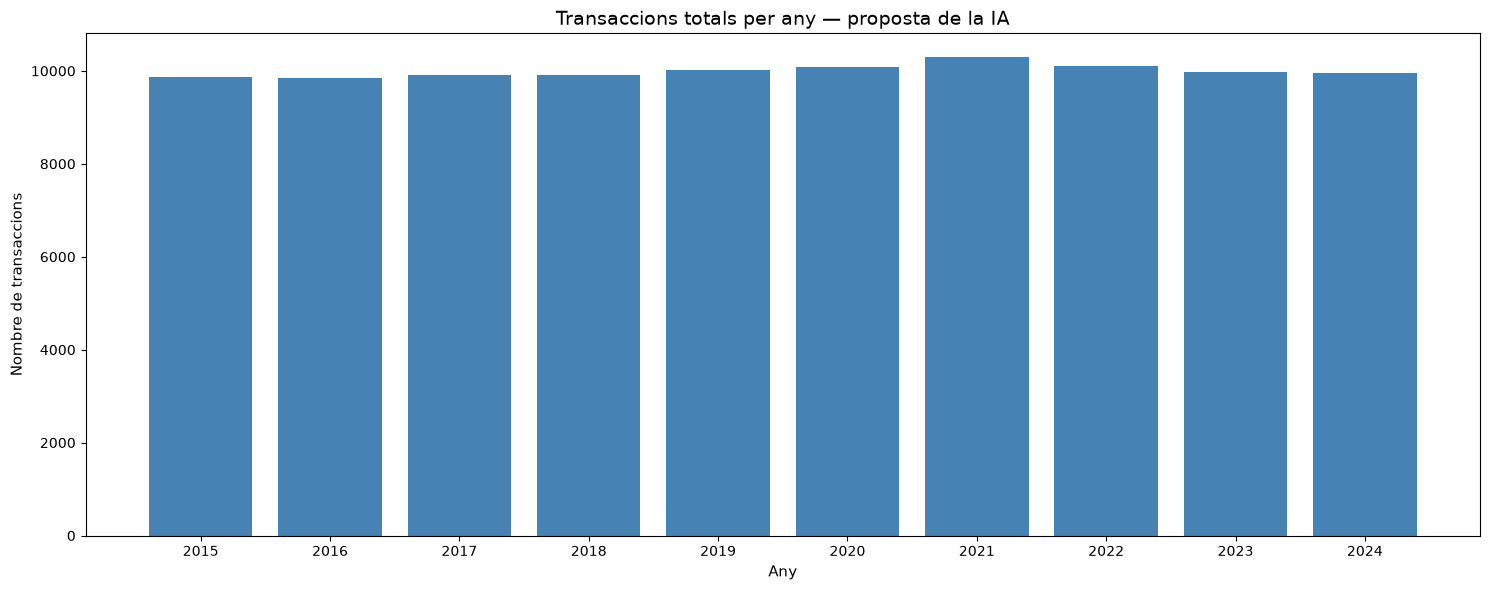

In [8]:
ax = plt.gca()
ax.bar(
    total_transactions_anuals.index.astype(str),
    total_transactions_anuals.values,
    color="steelblue"
)
ax.set_title("Transaccions totals per any — proposta de la IA")
ax.set_xlabel("Any")
ax.set_ylabel("Nombre de transaccions")
ax.set_ylim(bottom=0)
plt.show()

**Comparació crítica.** El gràfic de barres mostra més fidelment que les diferències entre anys són petites, perquè la seva escala comença a zero. En el gràfic de línies els canvis semblen més grans, ja que l'eix Y està retallat. **Prefereixo les línies per veure la tendència temporal**, especialment el canvi després de 2021, però considero les barres més adequades per comparar magnituds absolutes. Per a una comunicació pública, caldria advertir de l'escala retallada de la línia o emprar una escala que no distorsioni les diferències.

### 2. Quins usuaris generen més volum de facturació?

**Preparació de dades.** Utilitzo `user_id` (identificador categòric), `amount` (import de la transacció) i `declined` (estat). Converteixo els imports a format numèric i filtro `declined == 0` per comptabilitzar només les transaccions acceptades. Agrupo per usuari, sumo els imports amb `.sum()`, ordeno de més a menys i selecciono els **15 usuaris amb més facturació**.

In [9]:
df_transactions["declined"] = df_transactions["declined"].astype(int)
df_transactions["amount"] = df_transactions["amount"].astype(float)

facturacio_total = (df_transactions[df_transactions["declined"] == 0].groupby("user_id")["amount"].sum())
top15 = facturacio_total.sort_values(ascending=False).head(15)
display(top15)

user_id
289    47332.90
318    46393.44
455    40594.55
417    37393.91
185    34560.87
285    33217.28
454    29528.42
349    27835.38
193    27076.83
317    22484.76
388    20784.26
443    20605.24
319    20455.52
393    19154.68
437    18149.45
Name: amount, dtype: float64

**Selecció del gràfic inicial.** Utilitzo un **gràfic de barres horitzontals amb Seaborn**. A l'eix **Y** hi ha els identificadors dels usuaris i a l'eix **X** la facturació total. Els imports estan ordenats de més a menys, de dalt a baix; les barres horitzontals faciliten la lectura de categories i comparacions.

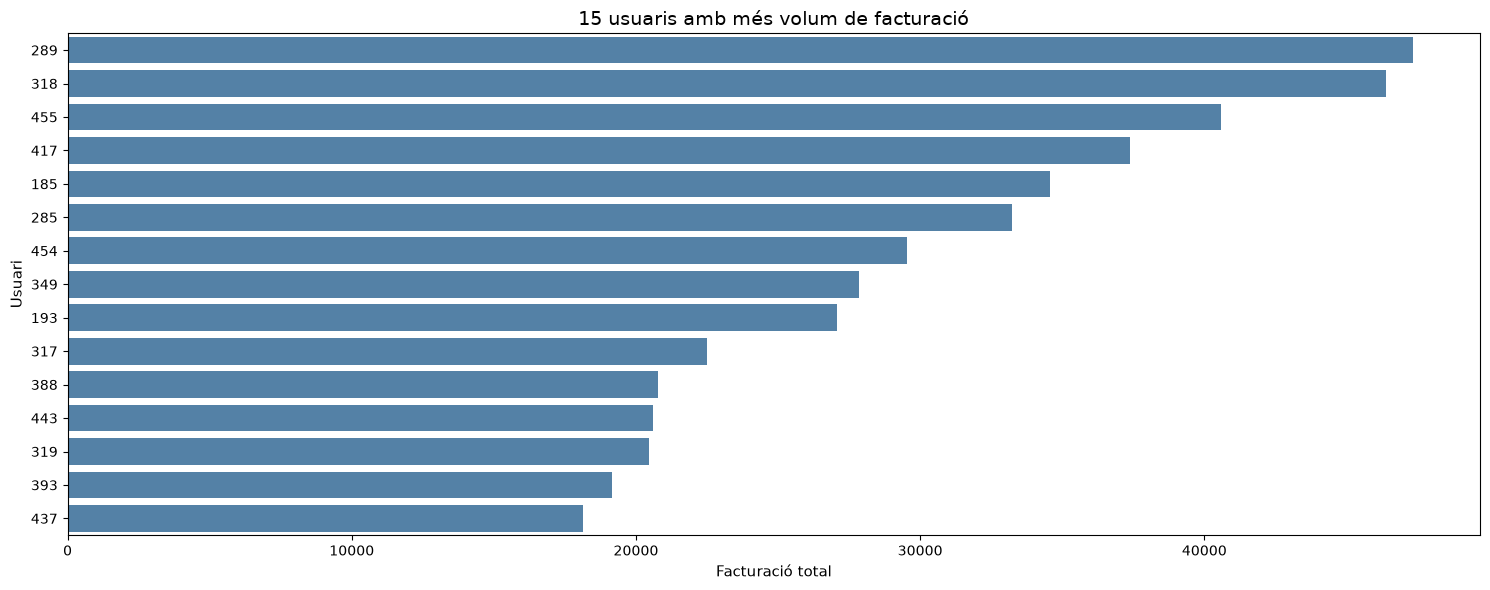

In [10]:
ax = sns.barplot(
    x=top15.values,
    y=top15.index.astype(str),
    color="steelblue"
)
ax.set_title("15 usuaris amb més volum de facturació")
ax.set_xlabel("Facturació total")
ax.set_ylabel("Usuari")
ax.set_xlim(left=0)
plt.show()

**Interpretació.** L'usuari **289** és el que genera més facturació (**47.332,90**), seguit dels usuaris **318 (46.393,44)** i **455 (40.594,55)**. L'import es redueix progressivament al llarg del rànquing. El gràfic ajuda a identificar els clients amb més pes en la facturació, tot i que caldria analitzar també la seva recurrència abans de prendre decisions comercials.

**Alternativa de la IA — Visual Studio (Chat with Copilot).**

> Como alternativa a las barras horizontales, te propongo un gráfico de tipo lollipop para el top 15. Mantiene los usuarios ordenados por facturación, pero con menos carga visual y los puntos destacan el importe de cada uno".

**Visualització alternativa: lollipop horitzontal.**

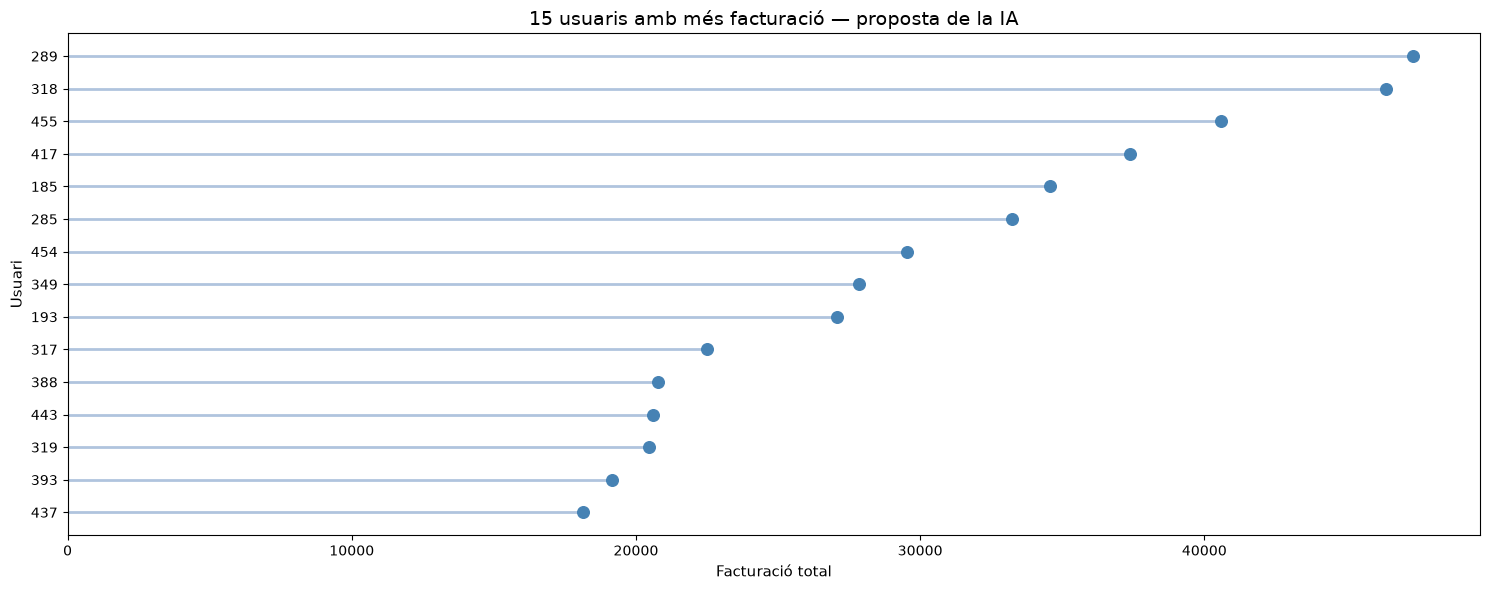

In [ ]:
fig, ax = plt.subplots()
y_usuaris = top15.index.astype(str)
ax.hlines(y=y_usuaris, xmin=0, xmax=top15.values,
          color="lightsteelblue", linewidth=2)
ax.scatter(top15.values, y_usuaris, color="steelblue", s=70, zorder=3)
ax.invert_yaxis()
ax.set_title("15 usuaris amb més facturació — proposta de la IA")
ax.set_xlabel("Facturació total")
ax.set_ylabel("Usuari")
ax.set_xlim(left=0)
plt.show()

**Comparació crítica.** El lollipop redueix l'àrea acolorida i ressalta el valor final amb un punt. Tot i això, **mantinc les barres horitzontals com a opció preferida**, perquè la seva longitud facilita comparar els imports i l'escala és fàcil de llegir. En tots dos gràfics el valor numèric queda a l'eix X perquè les categories són llargues i ordenades en forma de rànquing.

### 3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades?

**Preparació de dades.** Extrec l'hora de la columna `timestamp` amb `.dt.hour` (valors de 0 a 23). L'import de la transacció és `amount` (quantitativa) i l'estat és `declined` (categòrica: `0` acceptada, `1` rebutjada). A l'eix **X** situo les hores, a l'eix **Y** els imports i utilitzo `hue` per distingir els dos estats.

In [13]:
df_transactions["hora"] = df_transactions["timestamp"].dt.hour

**Selecció del gràfic inicial.** El violinplot de Seaborn permet comparar la distribució dels imports i observar en quins valors es concentren més les transaccions.

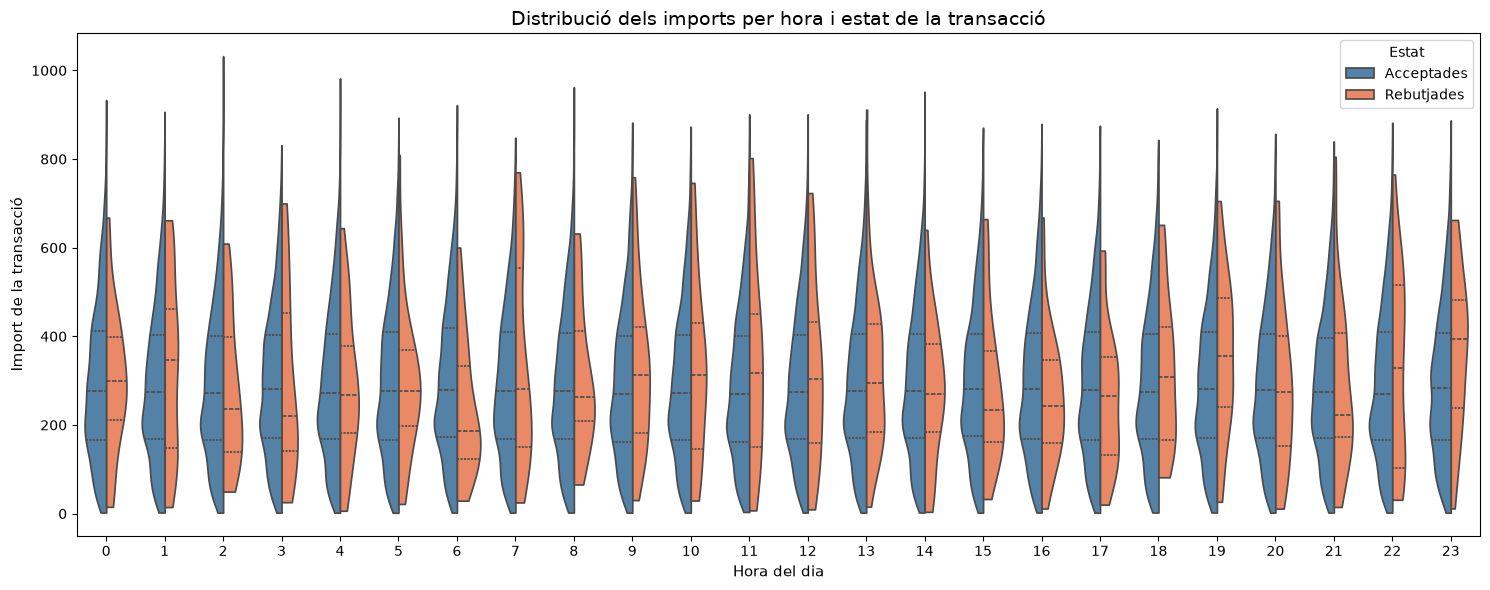

In [14]:
ax = sns.violinplot(
    data=df_transactions,
    x="hora",
    y="amount",
    hue="declined",
    hue_order=[0, 1],
    split=True,
    inner="quart",
    cut=0,
    palette={0: "steelblue", 1: "coral"}
)

ax.set_title("Distribució dels imports per hora i estat de la transacció")
ax.set_xlabel("Hora del dia")
ax.set_ylabel("Import de la transacció")

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=["Acceptades", "Rebutjades"], title="Estat")

plt.show()

**Interpretació.**

Els imports de les transaccions acceptades i rebutjades presenten distribucions força semblants al llarg del dia, sense un patró horari clar.
Les medianes se situen generalment entre els 200 i 350, amb algunes diferències puntuals entre els dos estats.
El violinplot mostra que la majoria dels imports es concentren en valors baixos i mitjans, mentre que els imports més elevats són menys freqüents.
En general, no s'observen diferències importants i constants segons l'hora del dia o l'estat de la transacció.

**Alternativa de la IA — Visual Studio (Chat with Copilot).**

Com a alternativa al violinplot del punt 3, et recomano un boxenplot. És adequat per comparar imports amb distribucions esbiaixades i mostra més detall dels quantils, mantenint la comparació per hora i per estat de la transacció.

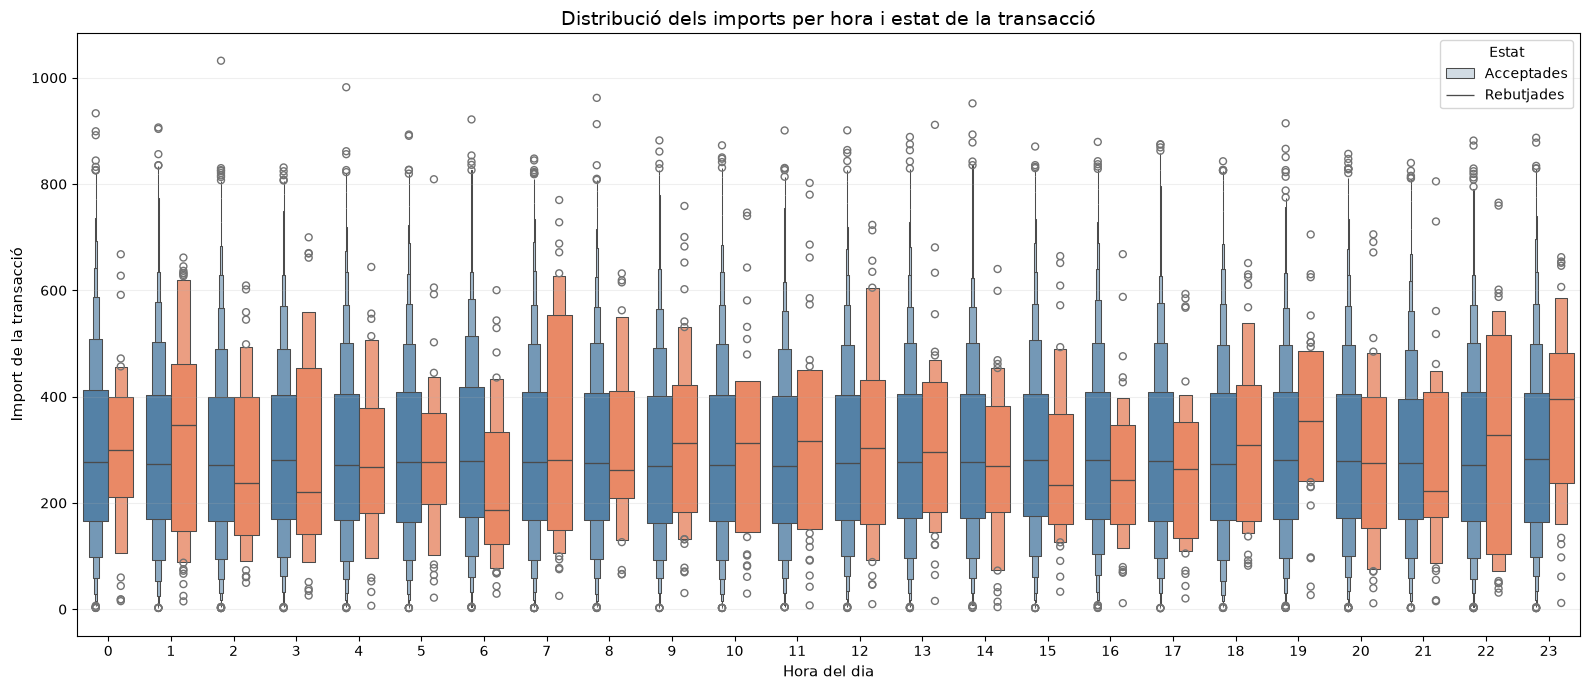

In [15]:
plt.figure(figsize=(16, 7))

ax = sns.boxenplot(
    data=df_transactions,
    x="hora",
    y="amount",
    hue="declined",
    hue_order=[0, 1],
    palette={0: "steelblue", 1: "coral"}
)

ax.set_title("Distribució dels imports per hora i estat de la transacció")
ax.set_xlabel("Hora del dia")
ax.set_ylabel("Import de la transacció")
ax.legend(title="Estat", labels=["Acceptades", "Rebutjades"])
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

#### Comparació crítica

Tots dos gràfics permeten comparar la distribució dels imports de les transaccions acceptades i rebutjades segons l'hora del dia.
El **violinplot** facilita veure on es concentren més els imports i comparar les dues distribucions gràcies a `split=True`. També mostra la mediana i els quartils.
El **boxenplot** ofereix més detall sobre la dispersió dels imports, els quantils i els valors extrems, però resulta més carregat visualment perquè tenim 24 hores i dos estats.

**Considero més adequat el violinplot**, perquè permet comparar les distribucions de manera més clara i identificar possibles diferències entre transaccions acceptades i rebutjades.


### 4. Quins dies de la setmana es concentra més activitat de venda?

**Preparació de dades.** A partir de `timestamp` genero `dia_setmana` amb `.dt.dayofweek` (0 = dilluns, 6 = diumenge), i relaciono els números amb el nom del dia. Filtro les transaccions acceptades (`declined == 0`), les compto amb `groupby()` i `.count()` i les ordeno amb `sort_index()` perquè els dies apareguin en l'ordre natural de dilluns a diumenge, no en un rànquing de més a menys.

In [16]:
df_transactions["dia_setmana"] = df_transactions["timestamp"].dt.dayofweek

dies = {
    0: "Dilluns",
    1: "Dimarts",
    2: "Dimecres",
    3: "Dijous",
    4: "Divendres",
    5: "Dissabte",
    6: "Diumenge"
}

transaccions_dia_setmana = (df_transactions[df_transactions["declined"] == 0].groupby("dia_setmana")["id"].count())
transaccions_dia_setmana_ordenat = transaccions_dia_setmana.sort_index()
display(transaccions_dia_setmana_ordenat)

dia_setmana
0    13996
1    14045
2    14153
3    14388
4    14138
5    14221
6    14171
Name: id, dtype: int64

**Selecció del gràfic inicial.** Les variables són `dia_setmana` (categories amb ordre temporal) i el recompte de transaccions acceptades (quantitativa). Utilitzo un **gràfic de barres verticals**, amb els dies a l'eix **X** i el nombre de transaccions a l'eix **Y**, que comença a zero.

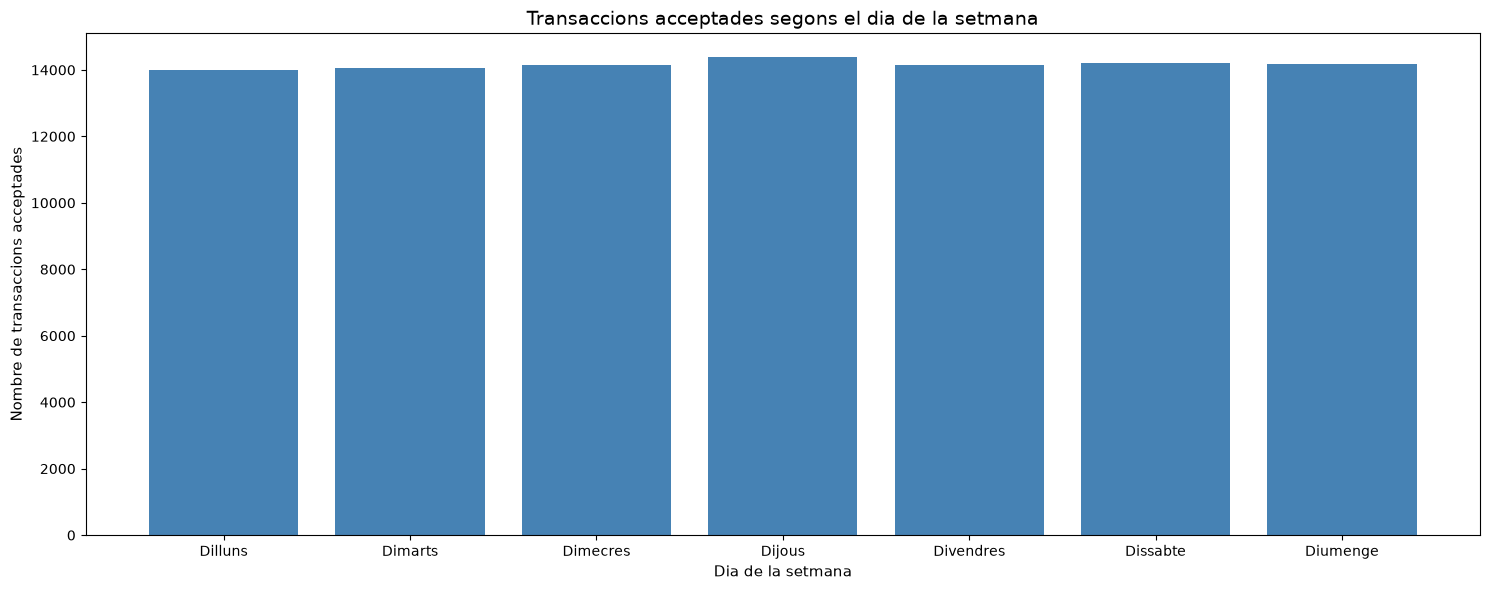

In [17]:
ax = plt.gca()
ax.bar(
    transaccions_dia_setmana_ordenat.index.map(dies),
    transaccions_dia_setmana_ordenat.values,
    color="steelblue"
)
ax.set_title("Transaccions acceptades segons el dia de la setmana")
ax.set_xlabel("Dia de la setmana")
ax.set_ylabel("Nombre de transaccions acceptades")
ax.set_ylim(bottom=0)
plt.show()

**Interpretació.** El **dijous** és el dia amb més activitat, amb **14.388 transaccions acceptades**, seguit del **dissabte**, amb **14.221**. Les diferències entre dies són petites i l'activitat de venda es distribueix de manera força uniforme al llarg de la setmana.

**Alternativa de la IA — Visual Studio (Chat with Copilot).**

> Com a alternativa al gràfic de barres, et proposo un gràfic lollipop. Manté l’ordre dels dies i facilita comparar les vendes sense omplir tot l’espai amb barres".

**Visualització alternativa: lollipop per dia de la setmana.**

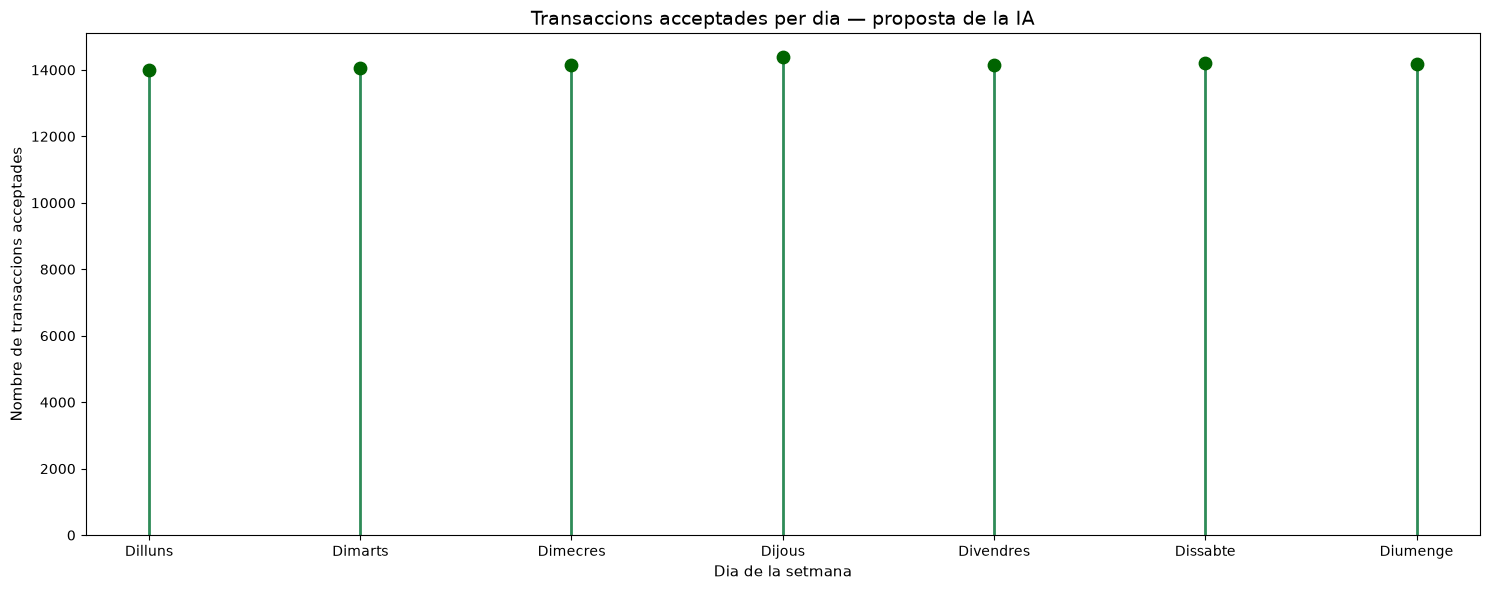

In [18]:
dies_setmana = transaccions_dia_setmana_ordenat.index.map(dies)
vendes = transaccions_dia_setmana_ordenat.values
fig, ax = plt.subplots()
ax.vlines(dies_setmana, 0, vendes, color="seagreen", linewidth=2)
ax.scatter(dies_setmana, vendes, color="darkgreen", s=80, zorder=3)
ax.set_title("Transaccions acceptades per dia — proposta de la IA")
ax.set_xlabel("Dia de la setmana")
ax.set_ylabel("Nombre de transaccions acceptades")
ax.set_ylim(bottom=0)
plt.show()

**Comparació crítica.** Els dos gràfics mostren que dijous és el dia de més activitat i que les diferències setmanals són moderades. El lollipop és més lleuger visualment; **mantinc el gràfic de barres**, perquè és més directe per comparar les quantitats. En tots dos casos mantinc l'ordre de dilluns a diumenge: ordenar per volum alteraria la seqüència temporal natural.

## Exercici 2: Preguntes analítiques complexes (amb guia)

🌍 Context: Aquest exercici requereix combinar informació de diverses taules del model per poder respondre correctament les preguntes.
Aquí sí que serà necessari:
- Fer merge entre taules.
- Utilitzar groupby, pivot_table, crosstab...
- Aplicar agregacions, transformacions intermèdies i funcions.

Preguntes analítiques (amb guia general)

» Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

1. Combinar la informació de transaccions amb la de companyies.

2. Agrupar la facturació per país.

3. Calcular la facturació total generada per cada país.

4. Ordenar els països de major a menor facturació.

5. Calcular el percentatge acumulat sobre el total.

6. Visualitzar.


» Existeix estacionalitat en les vendes?

Passos orientatius:

1. Treballar amb dates de transacció.

2. Extreure la informació temporal rellevant (any i mes).

3. Calcular el volum total de vendes (suma de amount) per any i mes.

4. Comparar patrons temporals amb la comparació entre anys. Crea una taula tipus pivot.

5. Visualitzar l'evolució.


» Anàlisi de concentració i variabilitat (tria UNA opció)

Opció A – Producte (Només si disposes de la taula de productes)

Quins productes generen més ingressos i amb quina variabilitat?

Passos orientatius:

1. Combinar transaccions, la taula pont i productes.

2. Calcular ingressos per producte amb un groupby, sum y sort.

3. Selecciona els top N productes: 15 per exemple.

4. Escollir una visualització adequada per analitzar dispersió.

Opció B – Activitat d'usuaris (Alternativa si no disposes de la taula de productes)

Hi ha usuaris que han deixat de comprar recentment?

Passos orientatius:

1. Identificar l'última compra per usuari.

2. Calcular el temps des de l'última compra.

3. Visualitzar la distribució del temps des de l'última compra.


» Com varia l'activitat de venda per franges horàries al llarg dels anys? (patrons horaris)

Passos orientatius:

1. Crear franges horàries a partir de l'hora: crea una funció i aplica-la utilitzant apply.

2. Construir una taula agregada utilitzant crosstab.

3. Visualitzar amb un heatmap.


👉 Per a cada pregunta:

- Descriu breument els passos seguits.

- Mostra la visualització final.

- Interpreta què implica per al negoci.



### 2.1 Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

1. Combinar la informació de transaccions amb la de companyies.

2. Agrupar la facturació per país.

3. Calcular la facturació total generada per cada país.

4. Ordenar els països de major a menor facturació.

5. Calcular el percentatge acumulat sobre el total.

6. Visualitzar.

### Preparació de les dades

Per analitzar la concentració de facturació per país, necessito combinar les dades de `transactions` amb les de `companies`, ja que la primera conté els imports i la segona el país de cada companyia.

Primer carrego la taula `companies` i reviso les columnes dels dos DataFrames per identificar com es relacionen.

Per assegurar-me que la relació és correcta, consulto les claus foranes (FK) definides a MySQL. Comprovo que `business_id` de transactions fa referència a `company_id` de companies.

In [19]:
df_companies = pd.read_sql(
    "SELECT * FROM companies",
    engine
)

display(df_companies.head())

,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,b-2222,Ac Fermentum Incorporated,+64 601 244 6320,donec.porttitor.tellus@yahoo.net,Germany,https://www.ac-fermentum-incorporated.com,Beauty,mid-market
1,b-2226,Magna A Neque Industries,+33 823 560 3779,risus.donec.nibh@icloud.org,Australia,https://www.magna-a-neque-industries.com,Travel,budget
2,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,b-2234,Convallis In Incorporated,+6 693 982 1255,mauris.ut@aol.couk,Germany,https://www.convallis-in-incorporated.com,Sports,mid-market
4,b-2238,Ante Iaculis Nec Foundation,+69 914 549 1009,sed.dictum.proin@outlook.ca,New Zealand,https://www.ante-iaculis-nec-foundation.com,Toys,mid-market


In [20]:
print(df_transactions.columns)
print(df_companies.columns)

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'any', 'hora', 'dia_setmana'],
      dtype='str')
Index(['company_id', 'company_name', 'phone', 'email', 'country', 'website',
       'merchant_category', 'merchant_price_position'],
      dtype='str')


In [21]:
consulta = """
SELECT
    COLUMN_NAME,
    REFERENCED_TABLE_NAME,
    REFERENCED_COLUMN_NAME
FROM information_schema.KEY_COLUMN_USAGE
WHERE TABLE_SCHEMA = DATABASE()
AND TABLE_NAME = 'transactions'
AND REFERENCED_TABLE_NAME IS NOT NULL
"""

display(pd.read_sql(consulta, engine))

,COLUMN_NAME,REFERENCED_TABLE_NAME,REFERENCED_COLUMN_NAME
0,business_id,companies,company_id
1,card_id,credit_cards,id
2,user_id,users,id


### Combinació de les taules

Faig un `merge()` utilitzant `business_id` i `company_id` com a claus de relació.

Utilitzo `how="left"` per mantenir totes les transaccions i afegir la informació de les companyies, especialment el país. D'aquesta manera puc relacionar cada import amb el país de la companyia venedora.

In [22]:
df_merge = df_transactions.merge(
    df_companies,
    left_on="business_id",
    right_on="company_id",
    how="left"
)

df_merge.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,hora,dia_setmana,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.19992926158272,1.4355402821327607,...,7,2,b-2458,Eget Tincidunt Dui Institute,+18 210 327 5206,eget.laoreet@hotmail.org,Netherlands,https://www.eget-tincidunt-dui-institute.com,Toys,mid-market
1,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,CcS-5019,b-2370,2016-12-21 20:07:18,172.56,0,"66, 69, 87",438,41.59720554463741,12.22175994259365,...,20,2,b-2370,Non Justo Corp.,+67 963 294 1666,urna.ut.tincidunt@yahoo.edu,Sweden,https://www.non-justo-corp.com,Fashion,budget
2,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757295899964348,-95.37963676492454,...,15,1,b-2390,Neque Tellus Imperdiet Corp.,+12 445 145 3593,vestibulum.ante.ipsum@aol.edu,Ireland,https://www.neque-tellus-imperdiet-corp.com,Food,budget
3,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.54888376797025,-113.50305274646564,...,19,0,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
4,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.20836951654172,5.690806474241335,...,18,3,b-2266,Mus Aenean Eget Foundation,+1 504 922 3000,mi.duis@hotmail.net,Sweden,https://www.mus-aenean-eget-foundation.com,Sports,mid-market


### Càlcul de la facturació per país

Agrupo les transaccions per `country` amb `groupby()` i sumo els imports de `amount`.
Així obtinc la facturació total de cada país i puc comparar quins generen més ingressos.

In [23]:
fact_total_paisos = df_merge[df_merge["declined"] == 0].groupby("country")["amount"].sum()
display(fact_total_paisos)

country
Australia          687532.20
Belgium            937789.26
Canada             552067.53
China              235421.76
France            1406668.15
Germany           3984664.03
Ireland            707379.30
Italy             4061060.93
Netherlands       4470873.59
New Zealand        696403.99
Norway             798331.87
Spain              452574.16
Sweden            4884250.39
United Kingdom    4065098.37
United States     1085266.88
Name: amount, dtype: float64

### Ordenació de la facturació

Ordeno els països de major a menor facturació amb `sort_values(ascending=False)`. Això permet identificar els països que més facturen i preparar les dades per calcular el percentatge acumulat.

In [24]:
fact_total_paisos_ordenada = fact_total_paisos.sort_values(ascending=False)
display(fact_total_paisos_ordenada)

country
Sweden            4884250.39
Netherlands       4470873.59
United Kingdom    4065098.37
Italy             4061060.93
Germany           3984664.03
France            1406668.15
United States     1085266.88
Belgium            937789.26
Norway             798331.87
Ireland            707379.30
New Zealand        696403.99
Australia          687532.20
Canada             552067.53
Spain              452574.16
China              235421.76
Name: amount, dtype: float64

### Càlcul dels percentatges

Calculo el percentatge que representa la facturació de cada país respecte al total.

Després utilitzo `cumsum()` per obtenir el percentatge acumulat, és a dir, quant sumen progressivament els països ordenats de major a menor facturació.

Finalment, creo un DataFrame resum amb la facturació total, el percentatge individual i l'acumulat. Això em permet veure si una part important dels ingressos es concentra en pocs països.

In [25]:
percentatge_pais = fact_total_paisos_ordenada / fact_total_paisos_ordenada.sum() * 100
percentatge_acumulat = percentatge_pais.cumsum()

df_resum_paisos = pd.DataFrame({
    "Facturació total": fact_total_paisos_ordenada,
    "% del total": percentatge_pais,
    "% acumulat": percentatge_acumulat
}).round(2)

display(df_resum_paisos)

,Facturació total,% del total,% acumulat
country,,,
Sweden,4884250.39,16.83,16.83
Netherlands,4470873.59,15.40,32.23
United Kingdom,4065098.37,14.01,46.24
Italy,4061060.93,13.99,60.23
Germany,3984664.03,13.73,73.96
France,1406668.15,4.85,78.80
United States,1085266.88,3.74,82.54
Belgium,937789.26,3.23,85.77
Norway,798331.87,2.75,88.52


### Selecció del gràfic

Les variables són `country` (categòrica nominal), facturació total (numèrica contínua) i percentatge acumulat (numèrica contínua).

He escollit un gràfic de Pareto perquè vull analitzar si la facturació està concentrada en un nombre reduït de països.

El gràfic combina barres, que mostren la facturació total de cada país, i una línia que representa el percentatge acumulat. També afegeixo una línia de referència del 80% per identificar quants països acumulen aquest percentatge de facturació.

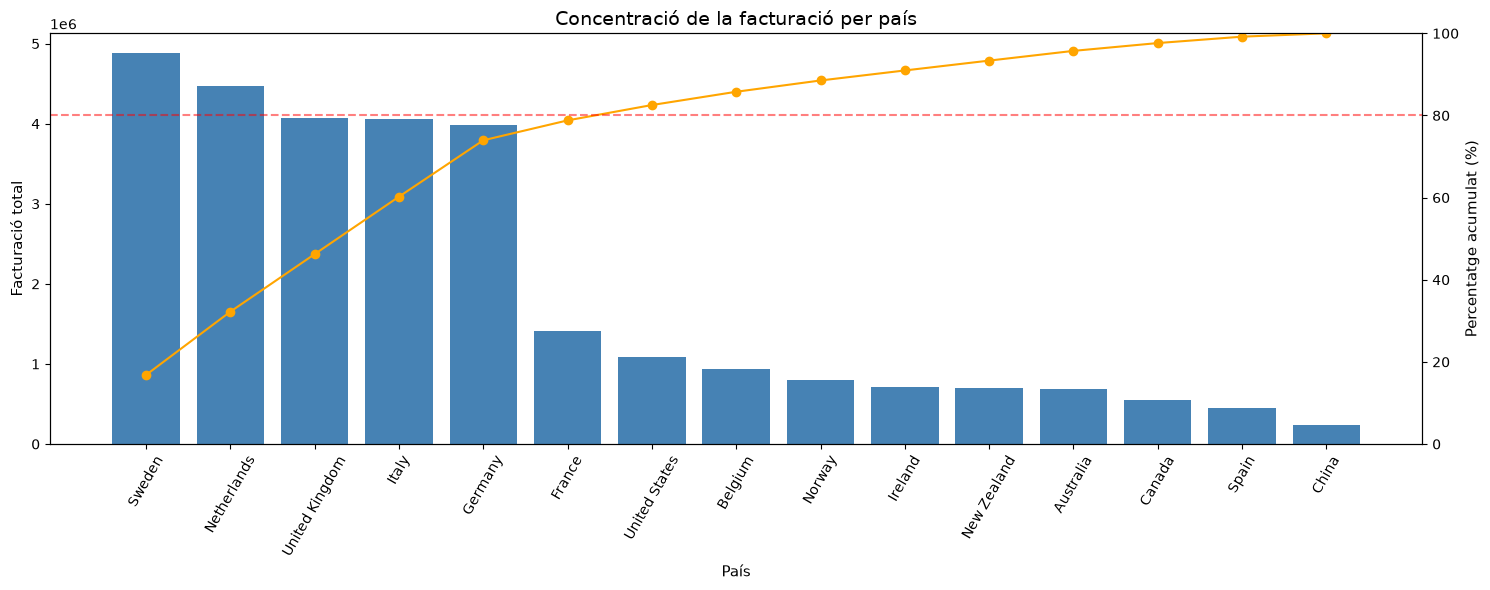

In [26]:
fig, ax1 = plt.subplots()

# BARRES: FACTURACIÓ TOTAL
ax1.bar(
    fact_total_paisos_ordenada.index,
    fact_total_paisos_ordenada.values,
    color="steelblue"
)

ax1.set_xlabel("País")
ax1.set_ylabel("Facturació total")
ax1.tick_params(axis="x", rotation=60)
ax1.set_ylim(bottom=0)

# LÍNIA: PERCENTATGE ACUMULAT
ax2 = ax1.twinx()  # Crea un segon eix Y

ax2.plot(
    percentatge_acumulat.index,
    percentatge_acumulat.values,
    color="orange",
    marker="o"
)

ax2.set_ylabel("Percentatge acumulat (%)")
ax2.set_ylim(0, 100)

# LÍNIA DE REFERÈNCIA DEL 80%
ax2.axhline(y=80, color="red", linestyle="--", alpha=0.5)

plt.title("Concentració de la facturació per país")
plt.tight_layout()
plt.show()

### Interpretació dels resultats

S'observa que Suècia, Països Baixos, Regne Unit, Itàlia i Alemanya concentren aproximadament el 74% de la facturació total.

La línia del percentatge acumulat creix més ràpidament en aquests primers països i després es va suavitzant, ja que la facturació de la resta és força inferior. Amb els 7 primers països se supera el 80% del total.

Per tant, sembla que el negoci depèn força d'aquests mercats, fet que podria suposar un risc si disminuïssin les vendes en algun d'ells.

Seria convenient estudiar oportunitats de creixement en altres països per diversificar els ingressos i reduir aquesta dependència.

### 2.2 Existeix estacionalitat en les vendes?

Passos orientatius:

1. Treballar amb dates de transacció.

2. Extreure la informació temporal rellevant (any i mes).

3. Calcular el volum total de vendes (suma de amount) per any i mes.

4. Comparar patrons temporals amb la comparació entre anys. Crea una taula tipus pivot.

5. Visualitzar l'evolució.

### Preparació de les dades - Estacionalitat de les vendes

Per analitzar si existeix estacionalitat en les vendes, necessito comparar la facturació dels mateixos mesos entre diferents anys.
Primer reviso les columnes temporals disponibles. Ja tinc creades `any_mes` i `any`, però necessito també el mes per separat.

Treballaré només amb les transaccions acceptades (`declined == 0`) i calcularé la facturació total per any i mes.

Després crearé una taula pivot amb els mesos a les files i els anys a les columnes, per poder comparar si hi ha mesos en què les vendes augmenten o disminueixen de manera habitual.

In [27]:
df_transactions.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,any,hora,dia_setmana
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",4713,46.19992926158272,1.4355402821327607,...,0.00,online,SUMMER_TRAVEL,mobile,0,,59.95,2024,7,2
1,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,CcS-5019,b-2370,2016-12-21 20:07:18,172.56,0,"66, 69, 87",438,41.59720554463741,12.22175994259365,...,6.99,online,CHRISTMAS_PEAK,tablet,0,,494.51,2016,20,2
2,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",2118,29.757295899964348,-95.37963676492454,...,0.00,store,SUMMER_TRAVEL,pos,1,,1157.10,2020,15,1
3,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2017-09-04 19:44:53,175.00,0,72,2115,53.54888376797025,-113.50305274646564,...,0.00,store,NO_CAMPAIGN,pos,0,,540.32,2017,19,0
4,00051AA4-9CBE-4268-B070-C38062A1B3E2,CcS-7606,b-2266,2017-01-05 18:19:25,158.55,0,18,3025,52.20836951654172,5.690806474241335,...,8.99,marketplace,WINTER_SALE,desktop,0,,28.52,2017,18,3


In [28]:
df_transactions["mes"] = df_transactions["timestamp"].dt.month

taula_pivot = pd.pivot_table(
    df_transactions[df_transactions["declined"] == 0],
    values="amount",
    index="mes",
    columns="any",
    aggfunc="sum"
)

display(taula_pivot)

any,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mes,,,,,,,,,,
1,221978.21,224451.27,222956.21,227411.90,222944.11,231702.95,243339.85,224709.53,228413.66,226393.73
2,245780.13,248112.42,252303.71,245092.09,259807.32,248318.04,257434.31,235427.85,251422.67,249898.07
3,253000.65,246634.37,237621.09,237099.83,276818.21,258872.56,250861.14,271978.12,241711.00,245792.02
4,245597.21,240833.04,251596.72,234246.30,242707.81,244251.90,259770.51,237165.49,241264.06,244769.15
5,248585.36,241306.84,240125.80,244448.97,242550.42,253699.74,239662.08,276262.60,261355.45,254122.62
6,232624.35,230577.43,240337.61,242769.22,241694.85,236410.96,234080.71,260082.37,232254.56,244370.81
7,241252.27,237081.73,240576.35,231261.73,233513.25,240255.64,251450.91,233349.01,238652.72,230031.53
8,233797.97,235600.88,230225.76,228759.89,237070.53,232658.86,237051.75,245198.95,237981.15,236671.63
9,227211.93,241530.84,230606.28,236768.38,232551.83,257964.96,245398.37,254316.72,234226.30,234226.89


### Selecció del gràfic

Les variables són `mes` i `any` (temporals discretes) i `amount` (numèrica contínua).

He escollit un gràfic de línies perquè vull comparar l'evolució de la facturació mensual entre els diferents anys i identificar possibles patrons d'estacionalitat.

Cada línia representa un any, cosa que permet observar si els augments i disminucions de les vendes es repeteixen en els mateixos mesos.

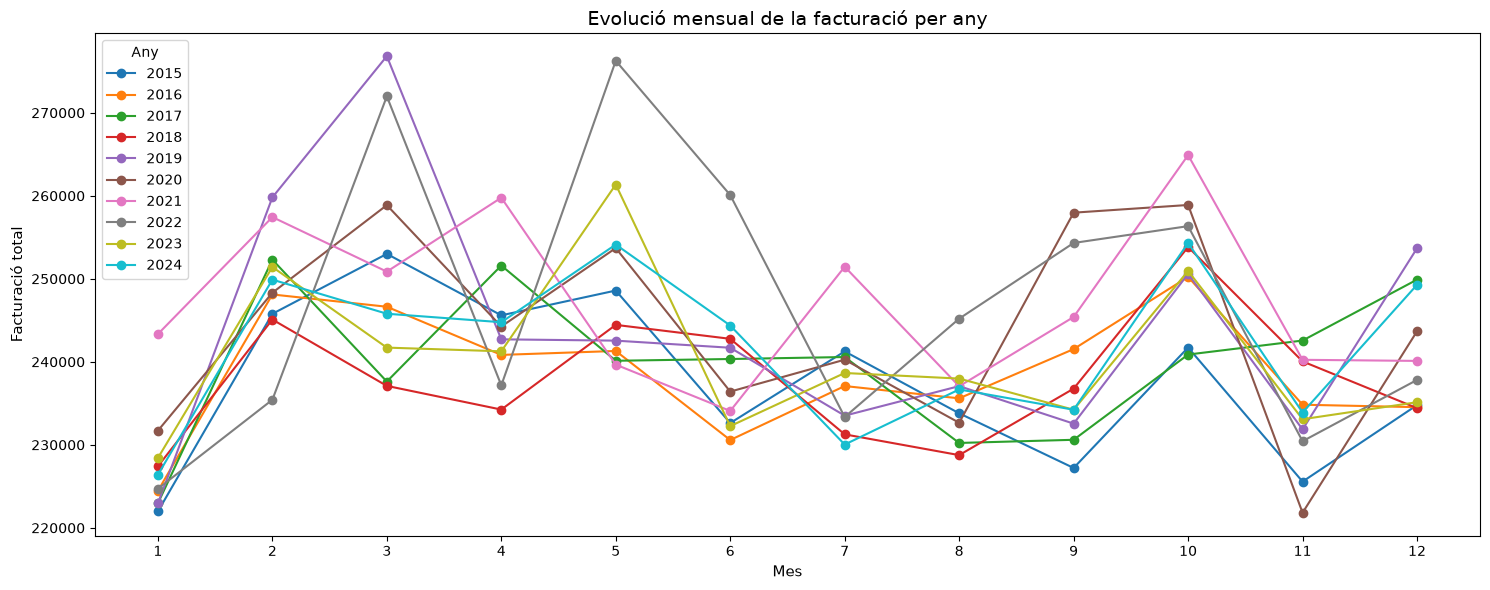

In [29]:
taula_pivot.plot(
    kind="line",
    marker="o",
    linewidth=1.5
)

plt.title("Evolució mensual de la facturació per any")
plt.xlabel("Mes")
plt.ylabel("Facturació total")

plt.xticks(range(1, 13))
plt.legend(title="Any")

plt.tight_layout()
plt.show()

### Interpretació dels resultats

S'observa una tendència a l'increment de la facturació durant el mes d'octubre, seguida d'una disminució força clara al novembre i una recuperació al desembre. També s'observa que el gener acostuma a presentar una facturació més baixa, que augmenta al febrer.

Per a la resta de mesos, els patrons varien segons els anys i no s'observa una tendència clara. Per tant, sembla que existeix una certa estacionalitat en les vendes, especialment en alguns mesos, però no és un patró constant durant tot l'any.

Aquests resultats poden ajudar l'empresa a planificar millor les vendes i els recursos durant l'any. Per exemple, es podrien estudiar possibles accions per incrementar les vendes durant els mesos amb menys facturació.

### 2.3 Anàlisi de concentració i variabilitat

#### Opció A – Producte: Quins productes generen més ingressos i amb quina variabilitat?

Passos orientatius:

1. Combinar transaccions, la taula pont i productes.

2. Calcular ingressos per producte amb un groupby, sum y sort.

3. Selecciona els top N productes: 15 per exemple.

4. Escollir una visualització adequada per analitzar dispersió.

### Preparació de les dades i identificació de les relacions

Per analitzar quins productes generen més ingressos, necessito combinar la informació de tres taules:

* `transactions`: conté les transaccions i els seus imports.
* `transaction_products`: és la taula pont que relaciona les transaccions amb els productes.
* `products`: conté la informació dels productes, com el nom i el preu.

Com que ja tinc carregada la taula `transactions`, carrego les altres dues taules des de MySQL mitjançant `pd.read_sql()`.

Abans de combinar-les, consulto les claus primàries (PK) i foranes (FK) definides a la base de dades, utilitzant `information_schema.KEY_COLUMN_USAGE`.

Aquesta consulta em permet identificar les columnes que relacionen les taules:

* `transactions.id` amb `transaction_products.transaction_id`.
* `transaction_products.product_id` amb `products.id`.

Un cop identificades les relacions, puc combinar correctament els tres DataFrames amb `merge()`.


In [30]:
df_transaction_products = pd.read_sql(
    "SELECT * FROM transaction_products",
    engine
)

df_products = pd.read_sql(
    "SELECT * FROM products",
    engine
)

display(df_transaction_products.head())
display(df_products.head())

,transaction_id,product_id
0,001A60EA-DC9C-4E5A-9460-6628B100E7E1,1
1,0032F0BB-BBE6-4AA5-B5EE-EEAD533C0C48,1
2,00342381-503D-422D-85AB-F2D4FFAAD4C7,1
3,004C0A80-E537-46D8-BE44-343D2176DF15,1
4,004D1DB5-B2CB-4460-98B6-31C42CA96E5F,1


,id,product_name,price,colour,wheight,warehouse_id,category,brand,cost,launch_date
0,1,Direwolf Stannis,$161.11,#7c7c7c,1.0,WH-4,Sports,Runway Pro,$63.84,2014-11-01
1,10,Karstark Dorne,$119.52,#f4f4f4,2.4,WH-5,Food,FreshBox,$89.07,2013-10-04
2,100,south duel,$40.43,#6d6d6d,3.0,WH-95,Electronics,PixelForge,$24.95,2013-01-05
3,11,Karstark Dorne,$49.70,#141414,2.7,WH-6,Electronics,Nexa,$34.45,2014-09-01
4,12,duel Direwolf,$181.60,#a8a8a8,2.1,WH-7,Gaming,Questbyte,$99.46,2013-10-11


In [31]:
consulta = """
SELECT
    TABLE_NAME AS taula,
    COLUMN_NAME AS columna,
    CONSTRAINT_NAME AS tipus_clau,
    REFERENCED_TABLE_NAME AS taula_referenciada,
    REFERENCED_COLUMN_NAME AS columna_referenciada

FROM information_schema.KEY_COLUMN_USAGE

WHERE TABLE_SCHEMA = DATABASE()
AND (
    CONSTRAINT_NAME = 'PRIMARY'
    OR REFERENCED_TABLE_NAME IS NOT NULL
)

ORDER BY TABLE_NAME, COLUMN_NAME;
"""

df_claus = pd.read_sql(consulta, engine)

display(df_claus)

,taula,columna,tipus_clau,taula_referenciada,columna_referenciada
0,companies,company_id,PRIMARY,NaN,NaN
1,credit_cards,id,PRIMARY,NaN,NaN
2,products,id,PRIMARY,NaN,NaN
3,transaction_products,product_id,PRIMARY,NaN,NaN
4,transaction_products,product_id,fk_product_id,products,id
5,transaction_products,transaction_id,PRIMARY,NaN,NaN
6,transaction_products,transaction_id,fk_transaction_id,transactions,id
7,transactions,business_id,fk_transactions_companies,companies,company_id
8,transactions,card_id,fk_transactions_credit_cards,credit_cards,id
9,transactions,id,PRIMARY,NaN,NaN


### Combinació de les taules amb merge()

Combino els tres DataFrames utilitzant dos `merge()` encadenats, sense necessitat de crear DataFrames intermedis.

Primer relaciono `transactions` amb `transaction_products`, utilitzant `id` i `transaction_id` com a claus.

Després incorporo la informació de `products`, relacionant `product_id` amb `id`.

En tots dos casos utilitzo `how="left"` per conservar les transaccions de la primera taula i afegir la informació disponible de les altres taules.

El resultat es guarda al DataFrame `df_merge_transaction_products`.

In [32]:
df_merge_transaction_products = (
    df_transactions.merge(
        df_transaction_products,
        left_on="id",
        right_on="transaction_id",
        how="left"
    ).merge(
        df_products,
        left_on="product_id",
        right_on="id",
        how="left"
    )
)

In [33]:
df_merge_transaction_products.columns

Index(['id_x', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'any', 'hora', 'dia_setmana', 'mes', 'transaction_id', 'product_id',
       'id_y', 'product_name', 'price', 'colour', 'wheight', 'warehouse_id',
       'category', 'brand', 'cost', 'launch_date'],
      dtype='str')

In [34]:
display(df_merge_transaction_products[
    ["id_x", "transaction_id", "product_id", "id_y", "product_name"]
].head(10))

,id_x,transaction_id,product_id,id_y,product_name
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,00043A49-2949-494B-A5DD-A5BAE3BB19DD,16,16,the duel warden
1,00043A49-2949-494B-A5DD-A5BAE3BB19DD,00043A49-2949-494B-A5DD-A5BAE3BB19DD,26,26,Stark Karstark
2,00043A49-2949-494B-A5DD-A5BAE3BB19DD,00043A49-2949-494B-A5DD-A5BAE3BB19DD,87,87,sith Jade
3,00043A49-2949-494B-A5DD-A5BAE3BB19DD,00043A49-2949-494B-A5DD-A5BAE3BB19DD,97,97,jinn Winterfell
4,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,66,66,mustafar jinn
5,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,69,69,Littlefinger the giantsblood
6,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,87,87,sith Jade
7,00045D6B-ED2E-4F2F-8186-CEE074D875D0,00045D6B-ED2E-4F2F-8186-CEE074D875D0,11,11,Karstark Dorne
8,00045D6B-ED2E-4F2F-8186-CEE074D875D0,00045D6B-ED2E-4F2F-8186-CEE074D875D0,16,16,the duel warden
9,00045D6B-ED2E-4F2F-8186-CEE074D875D0,00045D6B-ED2E-4F2F-8186-CEE074D875D0,30,30,Karstark warden


### Comprovació del resultat

Reviso les columnes del nou DataFrame amb `.columns` i observo que Pandas ha afegit els sufixos `_x` i `_y` per diferenciar les columnes `id` de les taules originals.

Per verificar les relacions, selecciono les columnes `id_x`, `transaction_id`, `product_id`, `id_y` i `product_name`, i visualitzo les 10 primeres files amb `head(10)`.

En aquesta mostra comprovo que:

* `id_x` coincideix amb `transaction_id`.
* `product_id` coincideix amb `id_y`.
* Els identificadors dels productes tenen associat un nom.

També observo que algunes transaccions apareixen repetides perquè contenen diversos productes. Això és normal en una relació d'un a molts (1:N).

Cal tenir-ho en compte en els càlculs posteriors, ja que la columna `amount` conté l'import de la transacció i es pot repetir per cada producte associat.

Per tant, abans de calcular els ingressos per producte, hauré de determinar quina variable representa correctament els ingressos que vull analitzar.


### Revisió i conversió del tipus de dades

Abans de calcular els ingressos per producte, comprovo els tipus de dades de les columnes `amount` i `price` amb `.dtypes`.

Observo que `amount` és de tipus `float64`, mentre que `price` és de tipus `str`, ja que els preus contenen el símbol `$`.

Per poder fer operacions matemàtiques, elimino aquest símbol amb `.str.replace()` i converteixo la columna a `float` mitjançant `.astype(float)`.

Finalment, comprovo que la conversió s'ha realitzat correctament.

In [35]:
df_merge_transaction_products[["price","amount"]].dtypes

price         str
amount    float64
dtype: object

In [36]:
df_merge_transaction_products["price"] = (
    df_merge_transaction_products["price"]
    .str.replace("$", "", regex=False)
    .astype(float)
)

In [37]:
df_merge_transaction_products["price"].dtype

dtype('float64')

In [38]:
df_comprovacio = (
    df_merge_transaction_products[
        df_merge_transaction_products["declined"] == 0
    ]
    .groupby("id_x")
    .agg(
        amount=("amount", "first"),
        suma_preus=("price", "sum")
    )
)

display(df_comprovacio.head(10))

,amount,suma_preus
id_x,,
00043A49-2949-494B-A5DD-A5BAE3BB19DD,433.51,395.43
000447FE-B650-4DCF-85DE-C7ED0EE1CAAD,172.56,155.63
00045D6B-ED2E-4F2F-8186-CEE074D875D0,332.38,326.01
000481C3-1C26-4FEF-83A0-4CD0EB004BBD,175.00,161.60
00051AA4-9CBE-4268-B070-C38062A1B3E2,158.55,148.91
0008A312-EDFE-4A4F-BC99-E9C92EC3CA4D,317.97,294.59
0009A151-9BCF-4E31-9053-A468FF77FAAB,457.51,383.63
0009D494-6245-4DF9-955D-2C084191CFFB,225.49,197.80
000A1DEC-CDB6-4AB2-A619-71DAB8D4A262,374.41,339.94


In [39]:
df_merge_transaction_products[
    ["tax_amount", "shipping_amount", "discount_amount"]
].dtypes

tax_amount         str
shipping_amount    str
discount_amount    str
dtype: object

In [40]:
columnes = ["tax_amount", "shipping_amount", "discount_amount"]

for col in columnes:
    df_merge_transaction_products[col] = (
        df_merge_transaction_products[col]
        .str.replace("$", "", regex=False)
        .astype(float)
    )

df_merge_transaction_products[
    ["tax_amount", "shipping_amount", "discount_amount"]
].dtypes

tax_amount         float64
shipping_amount    float64
discount_amount    float64
dtype: object

### Comprovació dels imports de les transaccions

Abans de calcular els ingressos per producte, vull comprovar si la suma dels preus dels productes coincideix amb l'import total de cada transacció.

Per fer-ho, filtro les transaccions acceptades (`declined == 0`) i les agrupo per identificador de transacció (`id_x`) mitjançant `groupby()`.

Utilitzo `.agg()` per aplicar dues operacions:

* `first` sobre `amount`, perquè l'import total es repeteix quan una transacció conté diversos productes.
* `sum` sobre `price`, per sumar els preus de tots els productes associats a cada transacció.

En comparar els resultats, observo que la suma dels preus no coincideix amb l'import total de les transaccions.

Com que també existeixen les columnes `tax_amount`, `shipping_amount` i `discount_amount`, considero que les diferències podrien correspondre als impostos, les despeses d'enviament i els descomptes aplicats.

Per comprovar-ho, reviso els tipus de dades d'aquestes tres columnes. Com que són de tipus `str`, utilitzo un bucle `for` per eliminar el símbol `$` i convertir-les a `float`.

A continuació, amplio l'agrupació anterior per incorporar aquests imports, utilitzant `first` perquè corresponen a la transacció i no s'han de sumar repetidament per cada producte.


In [41]:
df_comprovacio = (
    df_merge_transaction_products[
        df_merge_transaction_products["declined"] == 0
    ]
    .groupby("id_x")
    .agg(
        amount=("amount", "first"),
        suma_preus=("price", "sum"),
        impostos=("tax_amount", "first"),
        enviament=("shipping_amount", "first"),
        descompte=("discount_amount", "first")
    )
)

In [42]:
df_comprovacio["total_calculat"] = (
    df_comprovacio["suma_preus"]
    + df_comprovacio["impostos"]
    + df_comprovacio["enviament"]
    - df_comprovacio["descompte"]
).round(2)

df_comprovacio["diferencia"] = (
    df_comprovacio["amount"]
    - df_comprovacio["total_calculat"]
).round(2)

### Validació dels imports de les transaccions

Per comprovar els imports, calculo el total de cada transacció:

**Total = Preus dels productes + Impostos + Enviament − Descomptes**

Creo la columna `diferencia` per comparar el resultat amb `amount`, arrodonint a dos decimals.

Amb `.sum()` i les condicions `== 0` i `!= 0`, comprovo totes les transaccions acceptades.

**Resultat:**

* Transaccions analitzades: **99.112**
* Transaccions correctes: **99.112**
* Transaccions amb diferències: **0**

La fórmula coincideix en el 100% de les transaccions analitzades.

Per calcular els ingressos per producte, utilitzaré `price`, ja que `amount` correspon a tota la transacció i es repeteix després del `merge()`.



In [43]:
print("Total de transaccions:", len(df_comprovacio))

print("Transaccions correctes:",
      (df_comprovacio["diferencia"] == 0).sum())

print("Transaccions amb diferències:",
      (df_comprovacio["diferencia"] != 0).sum())

Total de transaccions: 99112
Transaccions correctes: 99112
Transaccions amb diferències: 0


### Càlcul dels ingressos per producte

Filtro les transaccions acceptades (`declined == 0`) i agrupo per `product_name` i `id_y`, per diferenciar productes que comparteixen el mateix nom.

Sumo els imports de `price` amb `sum()`, ordeno els resultats de major a menor amb `sort_values()` i selecciono els 15 productes principals amb `head(15)`.

Utilitzo `price` perquè representa el valor dels productes abans d'impostos, enviaments i descomptes.

In [44]:
ingressos_producte = df_merge_transaction_products[df_merge_transaction_products["declined"] == 0].groupby(["product_name","id_y"])["price"].sum().sort_values(ascending=False)

top15_productes = ingressos_producte.head(15)

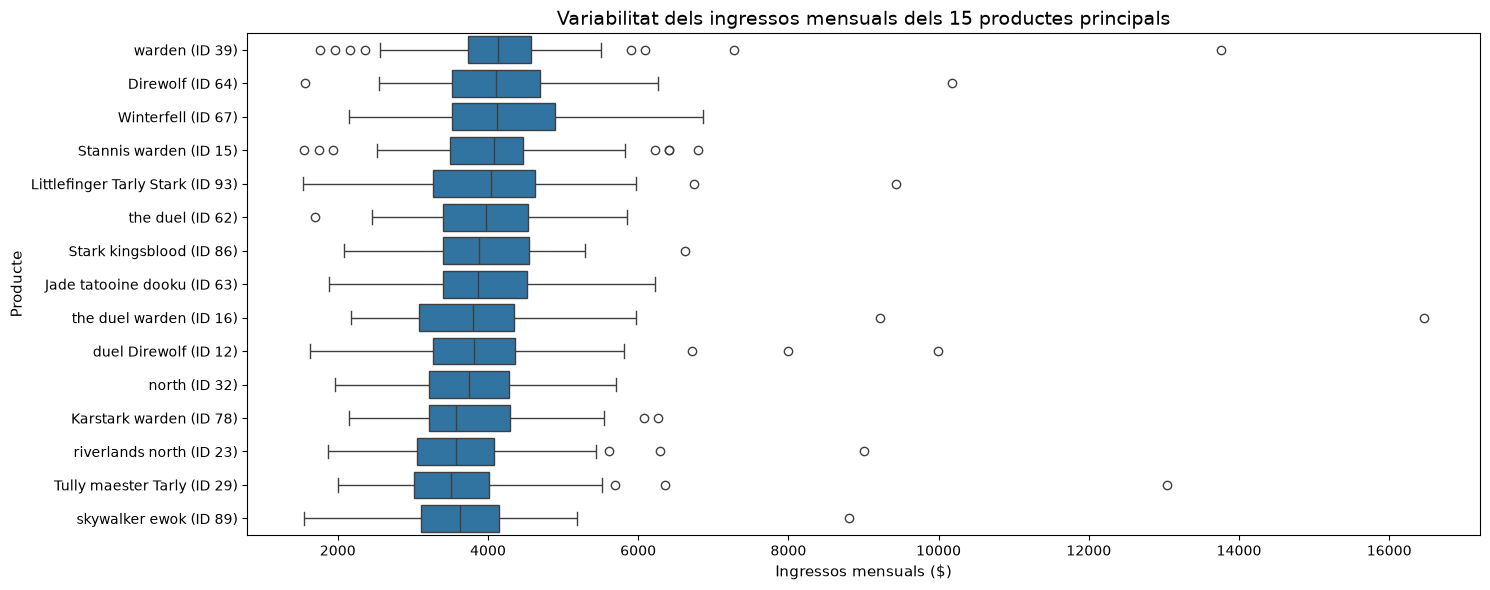

In [46]:
# Crear la columna any_mes per agrupar les vendes mensualment
df_merge_transaction_products["any_mes"] = (
    df_merge_transaction_products["timestamp"].dt.to_period("M")
)

# Seleccionar els 15 productes amb més ingressos
top_15 = ingressos_producte.head(15)
ids_top_15 = top_15.index.get_level_values("id_y")

# Filtrar les transaccions acceptades dels 15 productes
df_boxplot = df_merge_transaction_products[
    (df_merge_transaction_products["declined"] == 0) &
    (df_merge_transaction_products["id_y"].isin(ids_top_15))
].copy()

# Crear una etiqueta per diferenciar productes amb el mateix nom
df_boxplot["producte"] = (
    df_boxplot["product_name"] +
    " (ID " + df_boxplot["id_y"].astype(int).astype(str) + ")"
)

# Mantenir l'ordre dels 15 productes
ordre = [
    f"{nom} (ID {int(id_)})"
    for nom, id_ in top_15.index
]

# Calcular els ingressos mensuals per producte
df_ingressos_mes = (
    df_boxplot.groupby(["producte", "any_mes"], as_index=False)["price"].sum()
)

# Visualitzar la dispersió
sns.boxplot(
    data=df_ingressos_mes,
    x="price",
    y="producte",
    order=ordre
)

plt.title("Variabilitat dels ingressos mensuals dels 15 productes principals")
plt.xlabel("Ingressos mensuals ($)")
plt.ylabel("Producte")

plt.tight_layout()
plt.show()

### Visualització de la variabilitat dels ingressos per producte

Primer creo la columna `any_mes` a partir de `timestamp`, utilitzant `.dt.to_period("M")` per agrupar les transaccions per any i mes.

Selecciono els 15 productes amb més ingressos totals a partir de `ingressos_producte`.

Després calculo els ingressos mensuals de cada producte amb `groupby()` i `.sum()` sobre la columna `price`.
Utilitzo un **boxplot** perquè permet comparar la distribució dels ingressos mensuals i identificar diferències d'estabilitat, dispersió i valors atípics entre productes.


### Interpretació

Els ingressos mensuals centrals dels 15 productes són relativament semblants, amb medianes aproximades entre 3.000 i 4.200$.

Alguns productes presenten una dispersió més elevada, mentre que altres mantenen ingressos mensuals més regulars. També s'observen valors atípics més pronunciats, com `the duel warden (ID 16)`, `warden (ID 39)` i `Tully maester Tarly (ID 29)`. Si agafem com exemple, el producte `warden (ID 39)`, a comparació del `Winterfell (ID 67)`, podem dir que el primer presenta menys dispersió en el 50% central dels ingressos mensuals, cosa que indica més estabilitat en els ingressos habituals. No obstant això, també presenta mesos amb ingressos excepcionalment elevats (outliers).

**Conclusió:** Els productes amb més ingressos acumulats no necessàriament presenten la mateixa estabilitat mensual. Aquesta anàlisi permet identificar productes amb ingressos més previsibles i altres amb fluctuacions importants.
Aquesta informació pot ajudar a gestionar millor l'estoc, planificar les compres i identificar productes que necessiten un seguiment comercial més detallat.

**Limitació:** Els mesos sense vendes no s'han inclòs en el càlcul, fet que pot subestimar la variabilitat real. Tampoc podem saber a quins mesos corresponen els valors atípics. Per saber-ho, hauríem d'utilitzar un gràfic temporal (de línies, per exemple).

### 2.4 Com varia l'activitat de venda per franges horàries al llarg dels anys? (patrons horaris)

Passos orientatius:

1. Crear franges horàries a partir de l'hora: crea una funció i aplica-la utilitzant apply.

2. Construir una taula agregada utilitzant crosstab.

3. Visualitzar amb un heatmap.

In [47]:
df_transactions[df_transactions["declined"] == 0]["hora"].value_counts().sort_index()

hora
0     4085
1     4169
2     4050
3     4178
4     4161
5     4238
6     4128
7     4079
8     4179
9     4101
10    4120
11    4131
12    4171
13    4234
14    4165
15    4140
16    4112
17    4097
18    4131
19    4004
20    4039
21    4229
22    4073
23    4098
Name: count, dtype: int64

### Definició de les franges horàries

Abans de definir les franges, analitzo el nombre de transaccions acceptades per hora amb `value_counts()`.

Observo que l'activitat és força homogènia durant les 24 hores, sense diferències significatives a simple vista.

Per aquest motiu, decideixo dividir el dia en **quatre franges de sis hores**, per facilitar la comparació entre períodes de la mateixa durada:

* **Matinada:** 00:00–05:59
* **Matí:** 06:00–11:59
* **Tarda:** 12:00–17:59
* **Vespre/nit:** 18:00–23:59

**Limitació:** En un context real, seria necessari consultar amb l'empresa quins criteris de segmentació horària són més rellevants per al negoci i verificar la zona horària de les transaccions.


In [48]:
df_transactions["hora"].unique()

array([ 7, 20, 15, 19, 18,  4,  0,  5, 23,  9, 22, 11, 16,  2,  1, 10,  3,
       13, 21,  8,  6, 12, 17, 14], dtype=int32)

In [ ]:
def crear_franges_horaries(p_hora):
    if 0 <= p_hora <= 5:
        return "matinada"
    elif p_hora <= 11:
        return "matí"
    elif p_hora <= 17:
        return "tarda"
    else:
        return "vespre_nit"

df_transactions["Franges_horàries"] = df_transactions["hora"].apply(crear_franges_horaries)

display(df_transactions[["hora", "Franges_horàries"]])   
        

,hora,Franges_horàries
0,7,matí
1,20,vespre_nit
2,15,tarda
3,19,vespre_nit
4,18,vespre_nit
...,...,...
99995,20,vespre_nit
99996,3,matinada
99997,2,matinada
99998,19,vespre_nit


In [50]:
df_transactions.columns

Index(['id', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'any', 'hora', 'dia_setmana', 'mes', 'Franges_horàries'],
      dtype='str')

In [51]:
df_vendes = df_transactions[df_transactions["declined"] == 0]

### Preparació i visualització

Creo una funció amb `if/elif/else` per classificar les hores en quatre franges i l'aplico amb `.apply()`.

Filtro les transaccions acceptades (`declined == 0`) i utilitzo `pd.crosstab()` per comptar el nombre de vendes per franja horària i any.

Finalment, represento els resultats amb un **heatmap de Seaborn**, que permet comparar visualment l'activitat entre franges i anys mitjançant la intensitat del color.

In [52]:
taula_crosstab = pd.crosstab(
    index=df_vendes["Franges_horàries"],
    columns=df_vendes["any"]
)

display(taula_crosstab)

any,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Franges_horàries,,,,,,,,,,
matinada,2431,2454,2425,2496,2437,2591,2569,2548,2492,2438
matí,2443,2461,2456,2410,2536,2445,2555,2431,2528,2473
tarda,2425,2481,2531,2487,2526,2453,2569,2497,2448,2502
vespre_nit,2478,2374,2421,2430,2429,2520,2505,2539,2434,2444


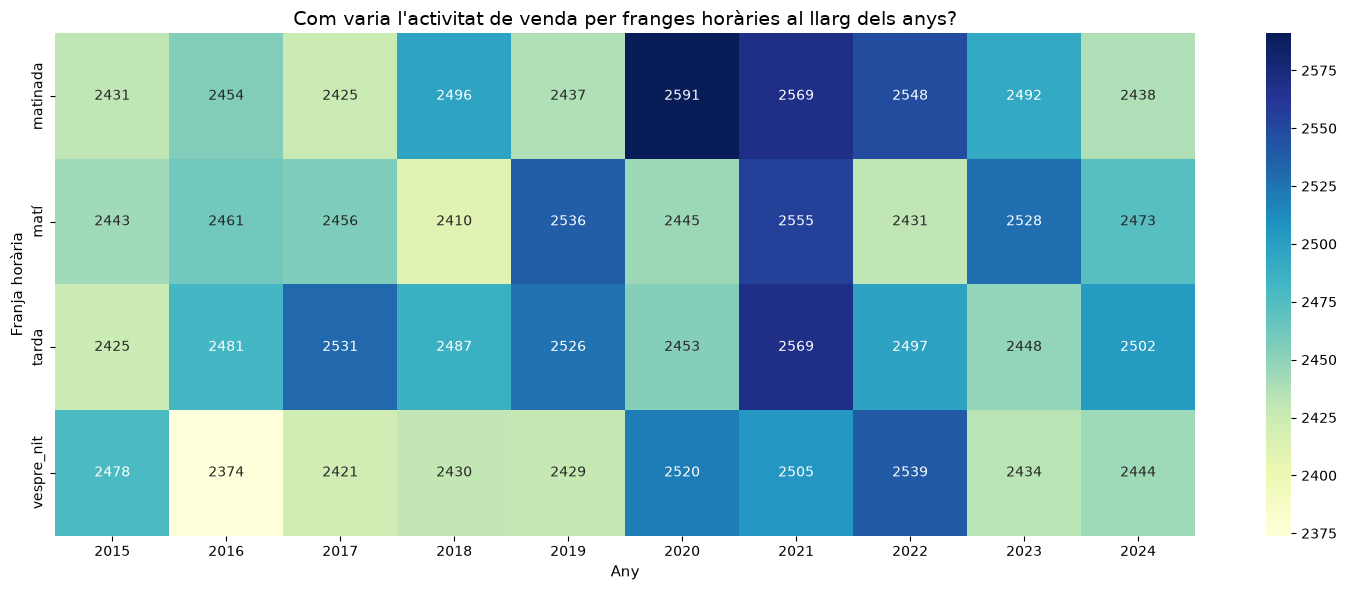

In [53]:
plt.figure()

sns.heatmap(
    data=taula_crosstab,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Com varia l'activitat de venda per franges horàries al llarg dels anys?")
plt.xlabel("Any")
plt.ylabel("Franja horària")

plt.show()

### Interpretació

En general, veiem que les vendes són bastant semblants en totes les franges horàries durant els anys 2015-2024. No hi ha cap franja que destaqui clarament per sobre de les altres.

Entre el 2020 i el 2022 sembla que hi ha més activitat durant la matinada i el vespre/nit, però aquesta tendència no es manté als altres anys. També veiem que les vendes de matinada van disminuint des del 2020 fins al 2024.

El 2021 sembla que hi ha més vendes en general, independentment de la franja horària.

**Conclusió:** No trobo un patró horari clar que es mantingui al llarg dels anys. Les diferències entre franges són petites i no sembla que hi hagi unes hores especialment millors per vendre.

Com que les vendes es distribueixen de manera força uniforme entre les franges horàries, no sembla necessari concentrar els recursos comercials en unes hores concretes.

L'empresa podria mantenir una disponibilitat del servei similar durant tot el dia, sense prioritzar una franja horària específica només per motius de volum de vendes.

# NIVELL 2 – Anàlisi relacional i patrons avançats

## Exercici 1: Anàlisi de productes i captació d'usuaris

🎯 Objectiu: Analitzar el rendiment dels productes combinant ingressos, estabilitat i capacitat de captació de nous usuaris, amb l'objectiu de detectar possibles riscos de negoci associats a concentració excessiva d'ingressos, dependència d'usuaris recurrents i manca de creixement en base d'usuaris.

Els productes que generen més ingressos també impulsen el creixement del negoci mitjançant la captació de nous usuaris, o bé el negoci depèn principalment d'usuaris recurrents comprant els mateixos productes? 

### 1. Combina les taules necessàries.

In [54]:
df_merge_transaction_products.columns

Index(['id_x', 'card_id', 'business_id', 'timestamp', 'amount', 'declined',
       'product_ids', 'user_id', 'lat', 'longitude', 'discount_amount',
       'tax_amount', 'shipping_amount', 'channel', 'campaign_id',
       'device_type', 'is_international', 'decline_reason', 'distance_km',
       'any', 'hora', 'dia_setmana', 'mes', 'transaction_id', 'product_id',
       'id_y', 'product_name', 'price', 'colour', 'wheight', 'warehouse_id',
       'category', 'brand', 'cost', 'launch_date', 'any_mes'],
      dtype='str')

Visualitzant les columnes de la taula `df_mwrge_transaction_products`, observem que NO és necessari combinar taules perquè ja existia aquesta taula prèviament combinada amb les dades necessàries per a respondre la pregunta de l'enunciat.

### 2. Defineix un criteri de nou usuari si la transacció analitzada és la primera cronològicament que realitza al sistema es_nou_usuari = True / False.

In [55]:
df_merge_filtrat = df_merge_transaction_products[df_merge_transaction_products["declined"] == 0].copy()

df_merge_filtrat["primera_compra"] = (df_merge_filtrat.groupby("user_id")["timestamp"].transform("min"))

df_merge_filtrat["es_nou_usuari"] = (df_merge_filtrat["timestamp"] == df_merge_filtrat["primera_compra"])

display(df_merge_filtrat[["user_id", "id_x", "timestamp", "primera_compra", "es_nou_usuari"]].sort_values(["user_id", "timestamp"]).head(15))

,user_id,id_x,timestamp,primera_compra,es_nou_usuari
110827,1,6ED484BC-2DBB-47CF-B77E-12752FCB43E2,2015-05-08 18:09:41,2015-05-08 18:09:41,True
110828,1,6ED484BC-2DBB-47CF-B77E-12752FCB43E2,2015-05-08 18:09:41,2015-05-08 18:09:41,True
110829,1,6ED484BC-2DBB-47CF-B77E-12752FCB43E2,2015-05-08 18:09:41,2015-05-08 18:09:41,True
241573,1,F3E47D02-CE43-4B87-8C3F-5B0D14526F41,2015-11-04 13:01:34,2015-05-08 18:09:41,False
241574,1,F3E47D02-CE43-4B87-8C3F-5B0D14526F41,2015-11-04 13:01:34,2015-05-08 18:09:41,False
241575,1,F3E47D02-CE43-4B87-8C3F-5B0D14526F41,2015-11-04 13:01:34,2015-05-08 18:09:41,False
150537,1,97693F29-668B-4289-8E37-0239AA395A97,2015-12-20 18:06:59,2015-05-08 18:09:41,False
150538,1,97693F29-668B-4289-8E37-0239AA395A97,2015-12-20 18:06:59,2015-05-08 18:09:41,False
127063,1,7F5C1DBA-F34B-4A4F-BCE9-51B6FF2AD633,2016-07-04 21:06:10,2015-05-08 18:09:41,False
2442,1,02800DB7-FAF0-4602-B28C-76FF7F8897EE,2016-09-22 02:43:55,2015-05-08 18:09:41,False


#### Identificació de nous usuaris per producte

1. **Filtratge de transaccions:** partim del DataFrame `df_merge_transaction_products` i seleccionem únicament les transaccions acceptades (`declined == 0`). Creem una còpia amb `.copy()` per treballar sense modificar les dades originals.

2. **Identificació de la primera compra:** agrupem les transaccions per `user_id` i utilitzem `transform("min")` sobre la columna `timestamp` per obtenir la data de la primera compra acceptada de cada usuari. Guardem el resultat en una nova columna anomenada `primera_compra`. `transform(min)`manté el nombre original de files i assigna a cada registre la data mínima del seu grup.

3. **Creació de la variable `es_nou_usuari`:** comparem el `timestamp` de cada registre amb la seva `primera_compra`. Aquesta comparació genera valors booleans:

   * `True`: el registre correspon a la primera compra de l'usuari.
   * `False`: correspon a una compra posterior.

### 3. Agrega la informació per producte i calcula les mètriques següents:

- Ingressos totals.
- Variabilitat dels ingressos.
- Nombre de nous usuaris.
- Percentatge de nous usuaris sobre el total de compradors del producte.

### Càlcul de les mètriques per producte

#### 3.1. Ingressos totals per producte

Reutilitzo la variable `ingressos_producte`, creada anteriorment al nivell 1.

Aquesta variable agrupa les transaccions acceptades per producte i suma la columna `price` mitjançant `.sum()`.

Utilitzo `price` en lloc d'`amount` perquè aquest últim representa l'import total de la transacció (productes, impostos, enviament i descomptes) i es repeteix per cada producte quan fem el `merge`. Per tant, sumar-lo provocaria duplicacions.

In [56]:
ingressos_producte = df_merge_transaction_products[df_merge_transaction_products["declined"] == 0].groupby(["product_name", "id_y"])["price"].sum().sort_values(ascending=False)

#### 3.2. Variabilitat dels ingressos per producte

Per analitzar l'estabilitat dels ingressos, primer creo `df_ingressos_mes`, agrupant les dades per `product_id` i `any_mes` i sumant els preus amb `.sum()`.
A diferència del nivell 1, en aquest cas analitzo tots els productes, no només els 15 amb més ingressos.
Després calculo la desviació estàndard dels ingressos mensuals de cada producte utilitzant `.std()` i arrodoneixo els resultats a dos decimals amb `.round(2)`.

* **Desviació estàndard alta:** els ingressos mensuals presenten més variabilitat.
* **Desviació estàndard baixa:** els ingressos mensuals són més constants.

Cal tenir en compte que aquest càlcul només considera els mesos amb vendes registrades. Els mesos sense vendes no s'inclouen com a valors zero.

In [57]:
df_ingressos_mes = (df_merge_filtrat.groupby(["product_id", "any_mes"], as_index=False)["price"].sum())
variabilitat_producte = (df_ingressos_mes.groupby("product_id")["price"].std().round(2))
display(variabilitat_producte)

product_id
1      1045.49
10      944.44
100     202.37
11      347.67
12     1094.67
        ...   
95       43.70
96      148.50
97      335.80
98      218.76
99      805.29
Name: price, Length: 100, dtype: float64

#### 3.3. Nombre de nous usuaris per producte

Utilitzo el DataFrame `df_merge_filtrat`, que ja conté la columna `es_nou_usuari`.
Primer selecciono els registres amb `es_nou_usuari == True`, corresponents a les primeres compres acceptades.
Després agrupo per `product_id` i aplico `.nunique()` sobre `user_id` per comptar el nombre d'usuaris nous diferents que han comprat cada producte.
Utilitzo `.nunique()` en lloc de `.count()` per evitar comptar diverses vegades un mateix usuari si ha comprat més d'una unitat del mateix producte.

In [58]:
total_nous_usuaris = df_merge_filtrat[df_merge_filtrat["es_nou_usuari"] == True].groupby("product_id")["user_id"].nunique()
display(total_nous_usuaris)

product_id
1      110
10     129
100    132
11     129
12     127
      ... 
95     124
96      99
97     121
98     120
99     125
Name: user_id, Length: 100, dtype: int64

#### 3.4. Percentatge de nous usuaris per producte

Primer calculo el nombre total de compradors diferents de cada producte, agrupant per `product_id` i aplicant `.nunique()` sobre `user_id`.
En aquest cas, considero tots els compradors, tant nous com recurrents.
Després calculo el percentatge dividint el nombre de nous usuaris (`total_nous_usuaris`) entre el total de compradors (`total_compradors`) i multiplicant el resultat per 100.
Finalment, arrodoneixo els resultats a dos decimals amb `.round(2)`.
Aquest percentatge permet comparar la capacitat de captació dels diferents productes, independentment del nombre total de compradors.
En els resultats obtinguts, els percentatges se situen aproximadament entre el 5% i el 7% per als productes mostrats.

In [59]:
total_compradors = df_merge_filtrat.groupby("product_id")["user_id"].nunique()
percentatge_nous = (total_nous_usuaris/total_compradors * 100).round(2)
display(percentatge_nous)

product_id
1      5.82
10     6.75
100    6.90
11     6.59
12     6.66
       ... 
95     6.47
96     5.18
97     6.39
98     6.20
99     6.51
Name: user_id, Length: 100, dtype: float64

### 4. Creació d'una tipologia analítica de productes a partir de les mètriques calculades, per exemple:

- Captador: alta captació de nous usuaris.
- Recurrent: ingressos elevats però baixa captació.
- Emergent: baixa facturació però bona captació.
- Estancat: baixos ingressos i baixa captació.

Per classificar els productes segons la facturació i la capacitat de captació de nous usuaris, utilitzo les mètriques calculades anteriorment.

Primer calculo la mediana dels ingressos i del percentatge de nous compradors per establir els llindars que diferencien els valors alts i baixos.

A partir d'aquests llindars, defineixo quatre categories:

* **Captador:** ingressos alts i captació alta.
* **Recurrent:** ingressos alts i captació baixa.
* **Emergent:** ingressos baixos i captació alta.
* **Estancat:** ingressos baixos i captació baixa.

Creo una funció amb condicions `if`, `elif` i `else` que retorna la categoria corresponent segons els ingressos i el percentatge de captació.

Després recorro els productes amb un bucle `for` i aplico la funció a cadascun, relacionant les dades mitjançant l'identificador del producte.

En els casos en què no hi ha nous compradors registrats, considero que la captació és del 0 %.

Finalment, guardo les classificacions en una Series de Pandas i utilitzo `value_counts()` per comptar quants productes pertanyen a cada tipologia.

Aquesta classificació permet identificar productes amb més capacitat de captació i detectar possibles dependències de compradors recurrents. Els llindars són relatius a les dades analitzades i no representen necessàriament objectius comercials.

In [60]:
llindar_ingressos = ingressos_producte.median()
llindar_captacio = percentatge_nous.median()

print("Mediana ingressos:", llindar_ingressos)
print("Mediana captació:", llindar_captacio)

Mediana ingressos: 248935.43
Mediana captació: 6.5


In [61]:
def classificar_producte(p_ingressos, p_captacio):
    if p_ingressos >= llindar_ingressos and p_captacio >= llindar_captacio:
        return "Captador"
    elif p_ingressos >= llindar_ingressos and p_captacio < llindar_captacio:
        return "Recurrent"
    elif p_ingressos < llindar_ingressos and p_captacio >= llindar_captacio:
        return "Emergent"
    else:
        return "Estancat"

In [62]:
classificacio_productes = {}

for (nom_producte, id_producte), ingressos in ingressos_producte.items():
    captacio = percentatge_nous.get(id_producte, 0)

    if pd.isna(captacio):
        captacio = 0

    classificacio_productes[(nom_producte, id_producte)] = classificar_producte(ingressos, captacio)


In [63]:
classificacio_productes = pd.Series(classificacio_productes, name="tipologia")

display(classificacio_productes)

warden                        39    Recurrent
Direwolf                      64    Recurrent
Winterfell                    67    Recurrent
Stannis warden                15    Recurrent
Littlefinger Tarly Stark      93    Recurrent
                                      ...    
giantsblood maester Karstark  75     Estancat
riverlands north Direwolf     95     Estancat
Direwolf Stannis              70     Emergent
Tully maester                 55     Estancat
mustafar jinn                 66     Emergent
Name: tipologia, Length: 100, dtype: str

In [64]:
display(classificacio_productes.value_counts())

tipologia
Recurrent    28
Emergent     28
Captador     22
Estancat     22
Name: count, dtype: int64

### 5. Construeix una visualització que permeti analitzar la relació entre les dimensions principals. Per exemple, un scatter plot amb:

- Eix X → ingressos totals per producte.
- Eix Y → nombre de nous usuaris.
- Mida del punt → variabilitat dels ingressos.
- Color del punt → tipologia analítica del producte.

#### Preparació de les dades i elecció del gràfic

Utilitzo un **gràfic de dispersió (`scatterplot`) de Seaborn** per comparar quatre aspectes de cada producte en una mateixa visualització:

- **Eix X:** ingressos totals del producte.
- **Eix Y:** nombre de nous usuaris que han comprat el producte.
- **Mida del punt (`size`):** variabilitat dels ingressos mensuals (desviació estàndard).
- **Color (`hue`):** tipologia assignada al punt anterior.

Com que `ingressos_producte` i `classificacio_productes` tenen un índex amb el nom i l'identificador del producte, faig servir `.droplevel(0)` per conservar l'ID. Després, amb `.reindex()`, alineo les altres mètriques amb aquests mateixos identificadors per evitar barrejar dades de productes diferents.

La mida del punt indica com fluctuen els ingressos mensuals, **no** el volum total de vendes. A més, la tipologia es defineix segons el **percentatge** de nous compradors, mentre que l'eix Y representa el **nombre** de nous usuaris: són dues mesures relacionades, però diferents.

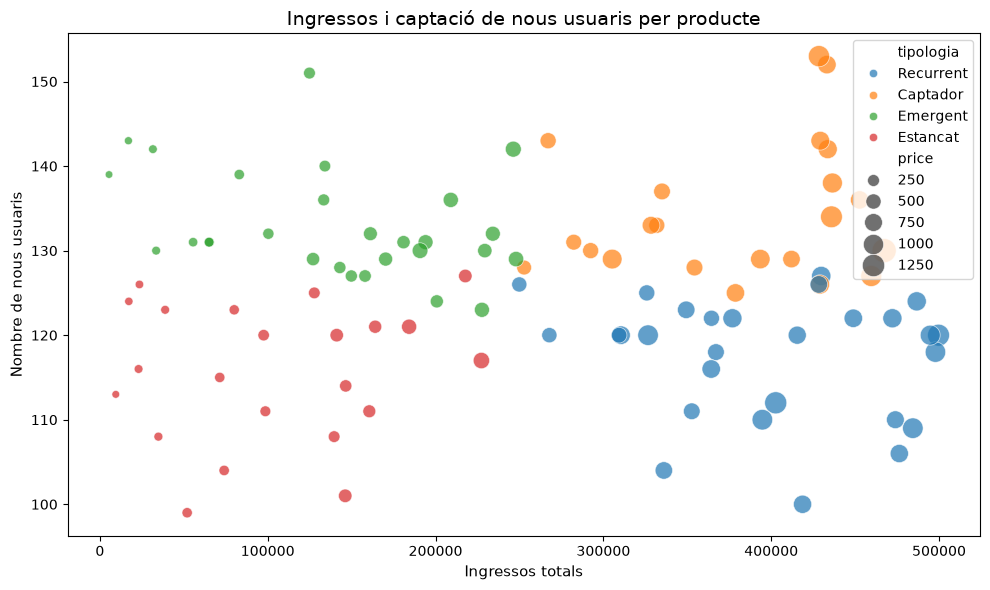

In [66]:
# Preparar les dades
ingressos = ingressos_producte.droplevel(0)

nous_usuaris = total_nous_usuaris.reindex(
    ingressos.index, fill_value=0
)

variabilitat = variabilitat_producte.reindex(
    ingressos.index
).fillna(0)

tipologia = classificacio_productes.droplevel(0).reindex(
    ingressos.index
)

# Crear el scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=ingressos,
    y=nous_usuaris,
    size=variabilitat,
    hue=tipologia,
    sizes=(30, 300),
    alpha=0.7
)

plt.title("Ingressos i captació de nous usuaris per producte")
plt.xlabel("Ingressos totals")
plt.ylabel("Nombre de nous usuaris")

plt.show()

#### Interpretació del gràfic i conclusions de negoci

El gràfic permet identificar quatre perfils de producte a partir de la combinació d'ingressos i captació:

- **Captadors (taronja):** apareixen a la zona de facturació alta i destaquen per una captació relativa de nous usuaris superior a la mediana. Són productes interessants per estudiar quines característiques afavoreixen l'atracció de clients.
- **Recurrents (blau):** també tenen ingressos elevats, però una captació relativa inferior. Convé seguir-ne l'evolució i valorar accions per atraure nous compradors, sense deixar de cuidar la clientela recurrent.
- **Emergents (verd):** tenen una facturació inferior a la mediana, però una captació relativa alta. Podrien tenir potencial de creixement, tot i que caldria analitzar-ne l'evolució en el temps.
- **Estancats (vermell):** queden per sota dels dos llindars. Seria útil revisar-ne la demanda, el posicionament o les accions comercials abans de prendre decisions.

Els punts presenten mides diferents, cosa que indica que **la variabilitat dels ingressos mensuals no és igual en tots els productes**. Per tant, una facturació acumulada elevada no ens garanteix per si sola uns ingressos estables mes a mes.

**Implicacions per al negoci**

L'anàlisi mostra que hi ha **28 productes recurrents** que generen ingressos elevats, però tenen un percentatge de captació de nous usuaris inferior a la mediana del 6,5 %.

Això no significa que aquests productes no captin nous compradors, però sí que tenen una captació relativa més baixa.

Si el negoci no aconsegueix atraure nous clients, podria tenir dificultats per continuar creixent, ja que dependria principalment de les compres dels usuaris habituals. A més, si aquests clients deixessin de comprar, la facturació podria disminuir.

Per reduir aquest risc, seria interessant potenciar la captació en els productes recurrents, analitzar què funciona en els productes captadors i valorar el potencial de creixement dels emergents.

**Conclusió:** captar nous usuaris és important per mantenir les oportunitats de creixement i reduir la dependència dels compradors habituals. Tot i això, amb les dades actuals no podem afirmar que el negoci tingui una dependència excessiva, ja que caldria analitzar també el pes de cada grup en la facturació total i l'evolució de la captació al llarg del temps.

**Limitacions:** he definit els nous usuaris a partir de la seva **primera compra acceptada** al conjunt de dades, no necessàriament de la seva primera transacció registrada. A més, la variabilitat mensual s'ha calculat només amb els mesos que tenen vendes; els mesos sense vendes no s'han incorporat com a zeros. Aquests criteris poden influir en la interpretació.